## 1. Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### ● Load the dataset into a Pandas DataFrame.

In [2]:
data = pd.read_csv('P721 DATASET.csv')

In [3]:
data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


In [4]:
data.tail()

,Date,Open,High,Low,Close,Adj Close,Volume
2006,2019-12-23,280.529999,284.250000,280.369995,284.000000,282.054138,24643000
2007,2019-12-24,284.690002,284.890015,282.920013,284.269989,282.322266,12119700
2008,2019-12-26,284.820007,289.980011,284.700012,289.910004,287.923645,23280300
2009,2019-12-27,291.119995,293.970001,288.119995,289.799988,287.814392,36566500
2010,2019-12-30,289.459991,292.690002,285.220001,291.519989,289.522614,36028600


## 2. Dataset Overview

In [5]:
data.shape

(2011, 7)

The dataset contains **2,011 rows and 7 columns**. The columns are `Date`, `Open`, `High`, `Low`, `Close`, `Adj Close`, and `Volume`. The price columns contain numerical values, while `Date` must be converted to datetime format for time-series analysis.

In [6]:
data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2011 entries, 0 to 2010
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2011 non-null   object 
 1   Open       2011 non-null   float64
 2   High       2011 non-null   float64
 3   Low        2011 non-null   float64
 4   Close      2011 non-null   float64
 5   Adj Close  2011 non-null   float64
 6   Volume     2011 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 110.1+ KB


In [8]:
data.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

The `isnull().sum()` function counts missing values in each column. The original dataset contains no missing values, so imputation is not required at this stage.


In [9]:
data.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2.011000e+03
mean,126.707469,127.827594,125.580258,126.741235,119.505548,5.949670e+07
std,50.483753,50.926301,50.124940,50.578369,52.438444,4.683856e+07
min,55.424286,57.085712,55.014286,55.790001,48.921928,1.136200e+07
25%,85.882858,86.717858,85.056427,86.202145,75.056679,2.758565e+07
50%,113.050003,114.190002,111.870003,113.050003,105.222908,4.346900e+07
75%,165.190002,167.409996,163.424995,165.245002,160.047111,7.471030e+07
max,291.119995,293.970001,288.119995,291.519989,289.522614,3.765300e+08


The `describe()` function provides descriptive statistics such as count, mean, standard deviation, minimum, quartiles, and maximum for the numerical variables. These statistics summarize the range and variability of Apple's stock prices and trading volume.

In [10]:
data.duplicated().sum()

np.int64(0)

The duplicate check identifies repeated complete rows. The original dataset has no duplicate rows, so no duplicate removal is required.


## 3. Data Cleaning and Preparation

### ● Convert the date column and sort observations chronologically.

In [11]:
data["Date"] = pd.to_datetime(data["Date"])

data = data.sort_values("Date").reset_index(drop=True)

print("Start date:", data["Date"].min())
print("End date:", data["Date"].max())

data.head()

Start date: 2012-01-03 00:00:00
End date: 2019-12-30 00:00:00


,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


## 4. Data Visualization

### ● Visualize the closing price trend over time.


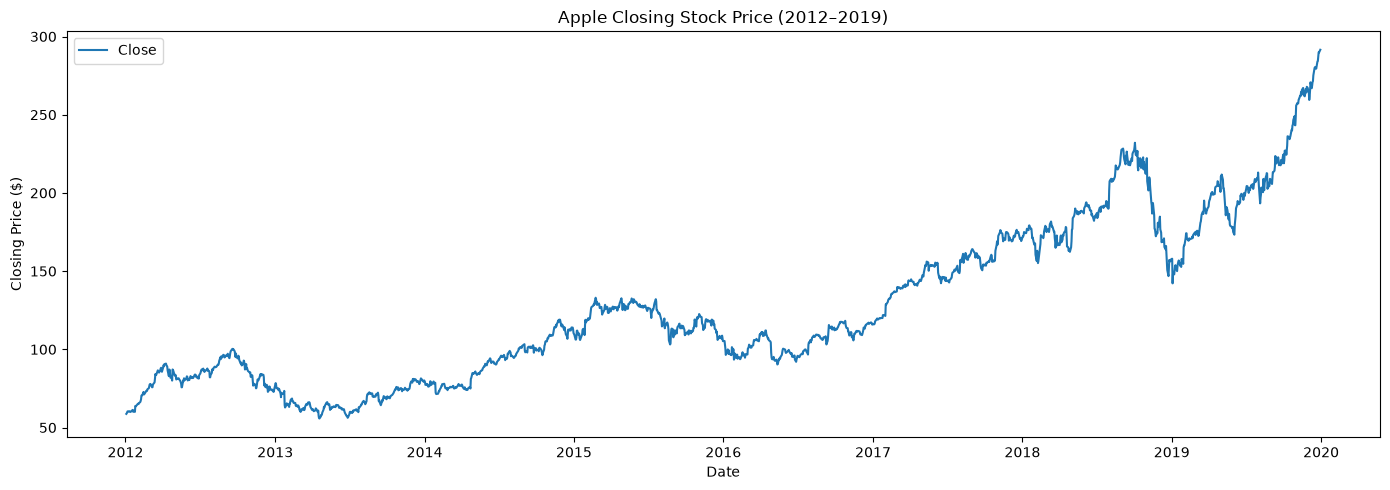

In [12]:
plt.figure(figsize=(14, 5))
plt.plot(data["Date"], data["Close"], label="Close")
plt.title("Apple Closing Stock Price (2012–2019)")
plt.xlabel("Date")
plt.ylabel("Closing Price ($)")
plt.legend()
plt.tight_layout()
plt.show()

The line chart shows how Apple's closing price changed over the observation period. Use the actual chart to identify long-term trends and periods of noticeable price movement.

### ● Compare Open, High, Low, and Close prices.

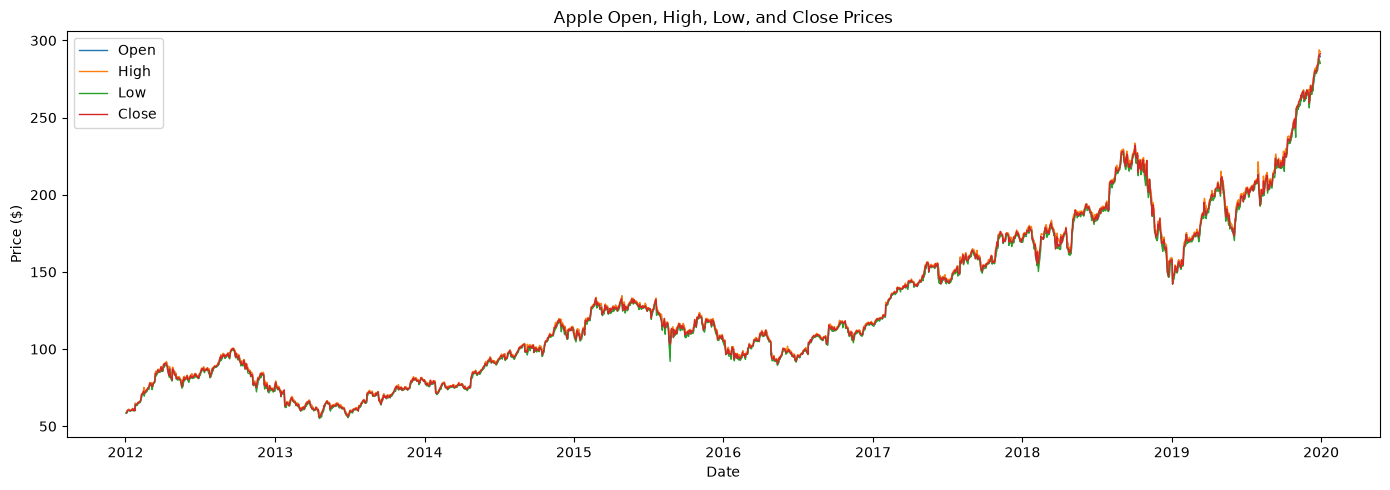

In [13]:
plt.figure(figsize=(14, 5))
for col in ["Open", "High", "Low", "Close"]:
    plt.plot(data["Date"], data[col], label=col, linewidth=1)
plt.title("Apple Open, High, Low, and Close Prices")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.tight_layout()
plt.show()

This multi-line chart compares the four daily price measurements. The High and Low values show the intraday price range, while Open and Close show the opening and closing prices.


 ### ● Visualize trading volume over time.

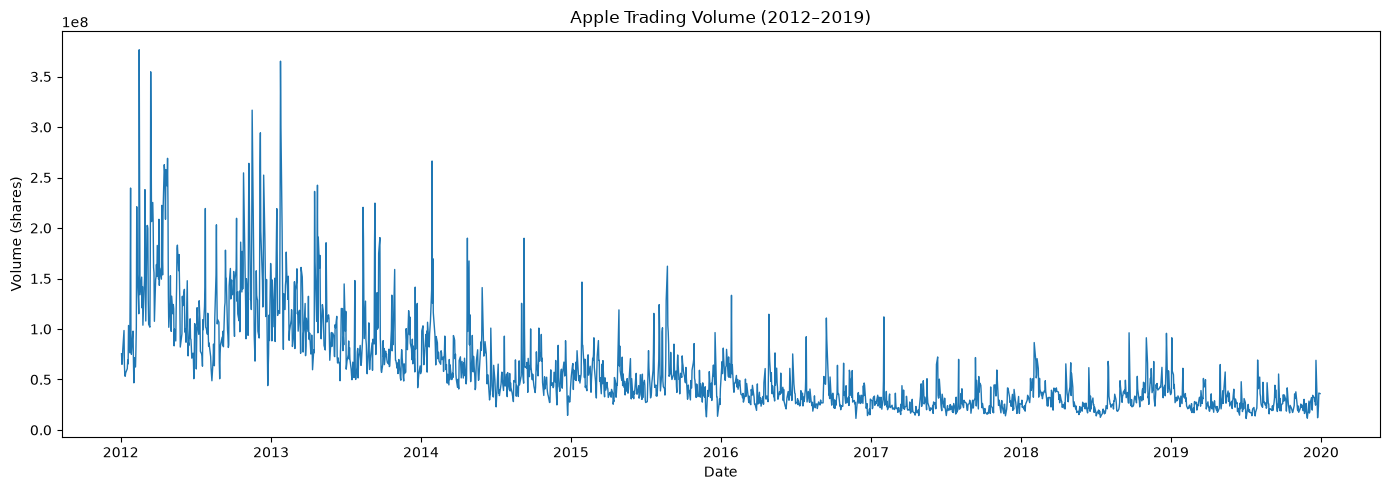

In [14]:
plt.figure(figsize=(14, 5))
plt.plot(data["Date"], data["Volume"], linewidth=1)
plt.title("Apple Trading Volume (2012–2019)")
plt.xlabel("Date")
plt.ylabel("Volume (shares)")
plt.tight_layout()
plt.show()

The chart shows changes in the number of shares traded. Peaks indicate periods of relatively high trading activity and can be compared with price movements for additional context.

### ● Visualize the distribution of closing prices.

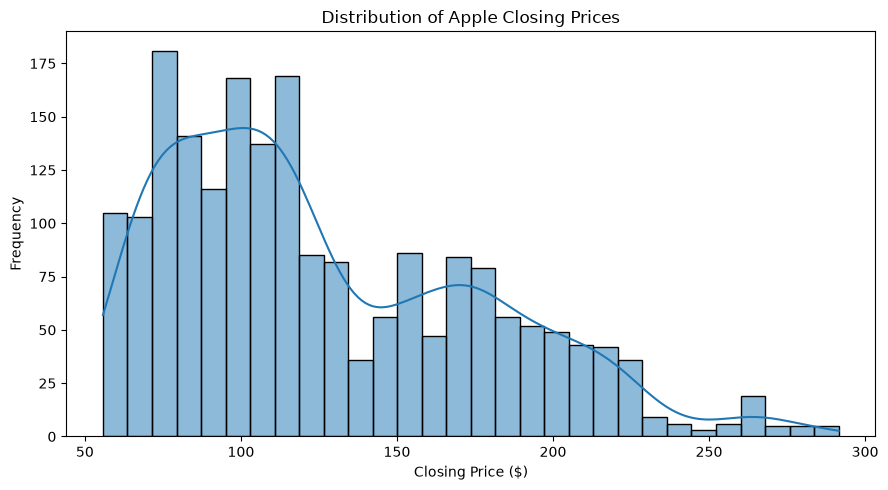

In [15]:
plt.figure(figsize=(9, 5))
sns.histplot(data["Close"], bins=30, kde=True)
plt.title("Distribution of Apple Closing Prices")
plt.xlabel("Closing Price ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

The histogram displays how often different closing price ranges occur. Since this combines prices across several years, the distribution reflects both the price trend over time and the frequency of observed values.

### ● Use boxplots to inspect numerical variables for potential outliers.

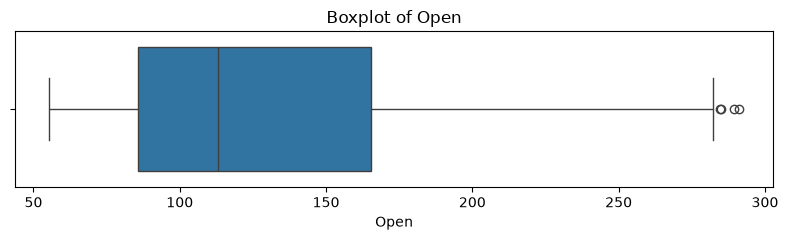

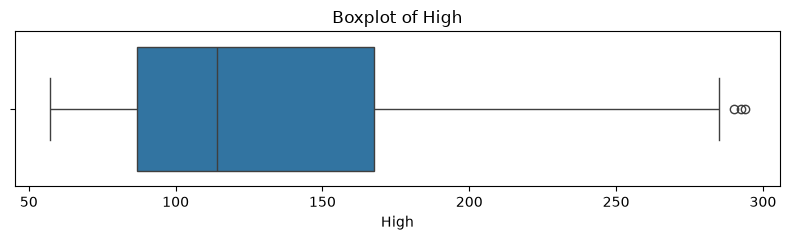

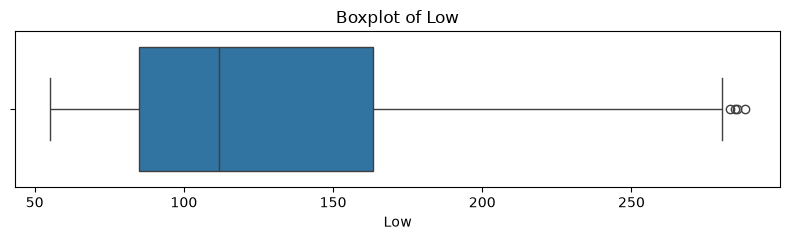

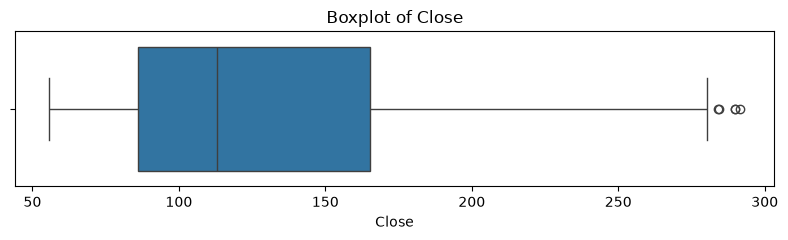

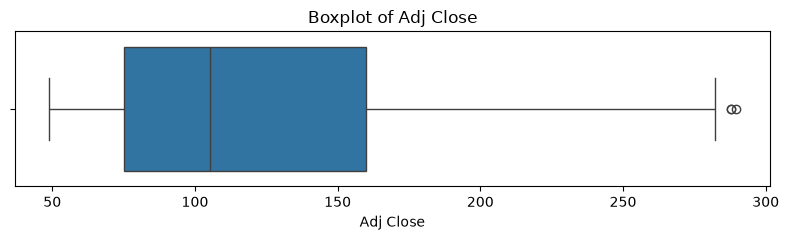

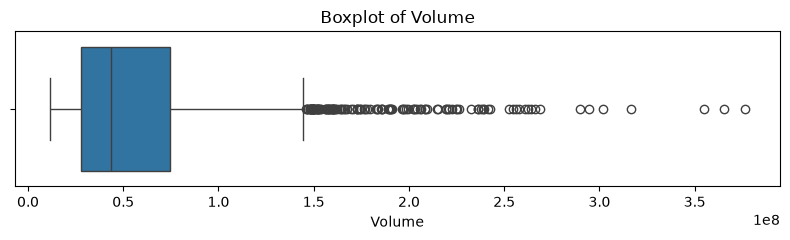

In [16]:
for col in ["Open", "High", "Low", "Close", "Adj Close", "Volume"]:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

Boxplots highlight observations that are far from the middle portion of each variable's distribution. In financial data, extreme values can be genuine market events; do not automatically delete them without investigation.


### ● Generate a correlation heatmap for numerical variables.

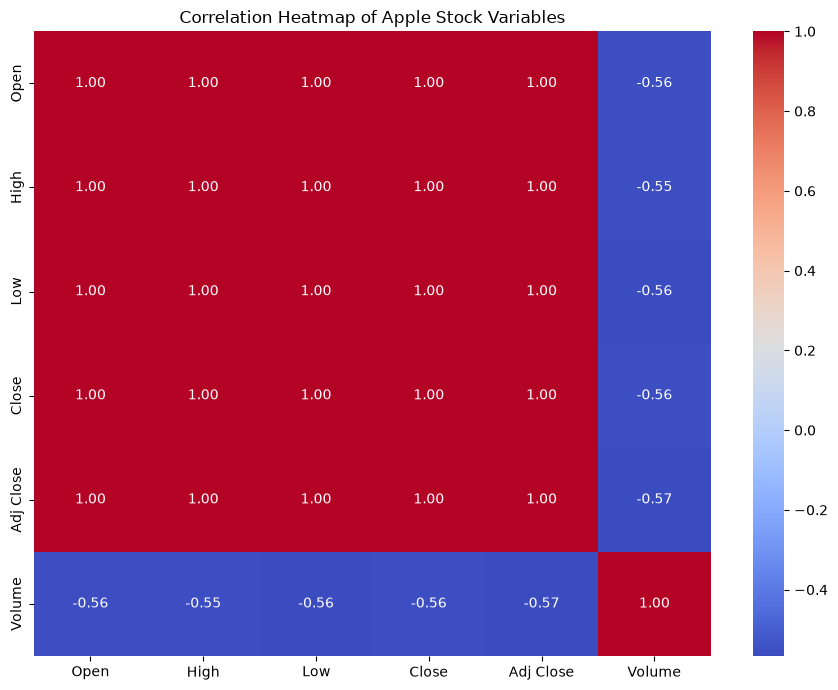

In [17]:
plt.figure(figsize=(9, 7))
corr = data[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Apple Stock Variables")
plt.tight_layout()
plt.show()

The heatmap displays pairwise linear correlations. Price variables may be strongly correlated because they measure the same stock over the same period. Correlation does not imply causation and does not by itself prove that a feature will improve forecasting.

## 5. Pattern Recognition: Daily Returns and Volatility

### ● Calculate daily percentage returns.

In [18]:
data["Daily_Return"] = data["Close"].pct_change()
data[["Date", "Close", "Daily_Return"]].head(10)

,Date,Close,Daily_Return
0,2012-01-03,58.747143,NaN
1,2012-01-04,59.062859,0.005374
2,2012-01-05,59.718571,0.011102
3,2012-01-06,60.342857,0.010454
4,2012-01-09,60.247143,-0.001586
5,2012-01-10,60.462856,0.003580
6,2012-01-11,60.364285,-0.001630
7,2012-01-12,60.198570,-0.002745
8,2012-01-13,59.972858,-0.003749
9,2012-01-17,60.671429,0.011648


Daily return measures the proportional change in closing price from the previous trading observation. Positive values indicate an increase and negative values indicate a decrease. The first value is missing because there is no previous observation.


### ● Visualize daily returns over time.

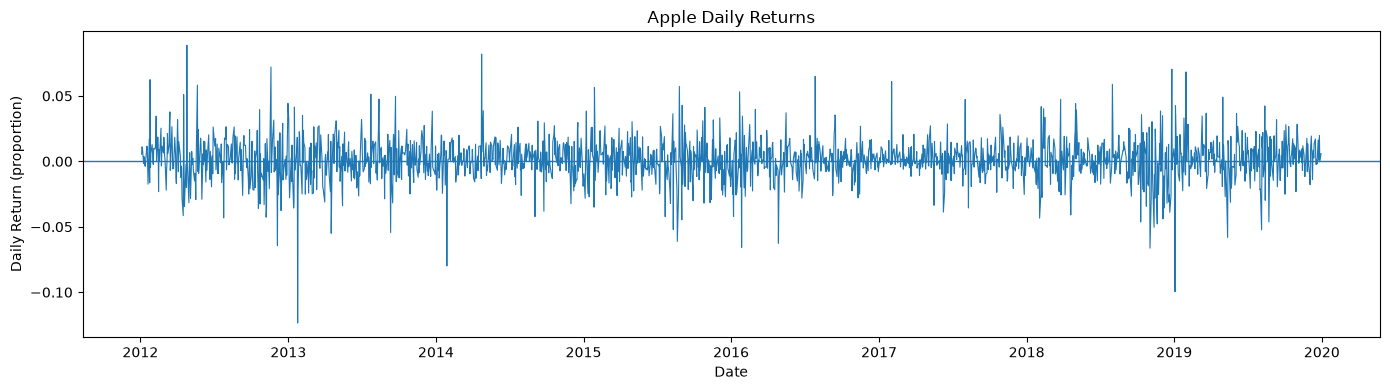

In [19]:
plt.figure(figsize=(14, 4))
plt.plot(data["Date"], data["Daily_Return"], linewidth=0.8)
plt.axhline(0, linewidth=1)
plt.title("Apple Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (proportion)")
plt.tight_layout()
plt.show()

The daily return chart highlights positive and negative price changes. Large spikes indicate relatively large daily movements and should be investigated rather than automatically treated as errors.


### ● Calculate and visualize 20-trading-day rolling volatility.


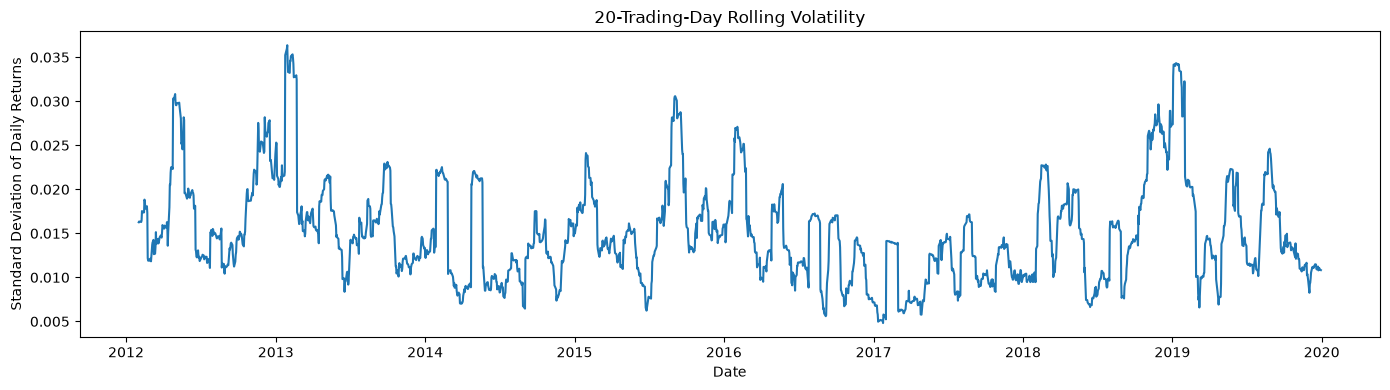

In [20]:
data["Volatility_20"] = data["Daily_Return"].rolling(window=20).std()

plt.figure(figsize=(14, 4))
plt.plot(data["Date"], data["Volatility_20"])
plt.title("20-Trading-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Standard Deviation of Daily Returns")
plt.tight_layout()
plt.show()


Rolling volatility is the standard deviation of daily returns over the latest 20 trading observations. Higher values indicate more variable recent returns; lower values indicate relatively stable returns. The initial rolling values are missing because a full window is not yet available.


## 6. Feature Engineering

### ● Create 7-day and 30-day moving averages.

In [21]:
data["MA_7"] = data["Close"].rolling(window=7).mean()
data["MA_30"] = data["Close"].rolling(window=30).mean()

data[["Date", "Close", "MA_7", "MA_30"]].tail(10)

,Date,Close,MA_7,MA_30
2001,2019-12-16,279.859985,271.907139,264.962334
2002,2019-12-17,280.410004,273.292855,265.726001
2003,2019-12-18,279.739990,275.124281,266.479667
2004,2019-12-19,280.019989,276.772849,267.239000
2005,2019-12-20,279.440002,278.011422,267.906001
2006,2019-12-23,284.000000,279.802852,268.701334
2007,2019-12-24,284.269989,281.105708,269.436999
2008,2019-12-26,289.910004,282.541425,270.368667
2009,2019-12-27,289.799988,283.882852,271.212999
2010,2019-12-30,291.519989,285.565709,272.175665


`MA_7` is the average closing price over the latest 7 trading observations, and `MA_30` is the average over the latest 30 trading observations. Moving averages smooth short-term fluctuations and help describe recent price trends.


### ● Plot closing price with moving averages.

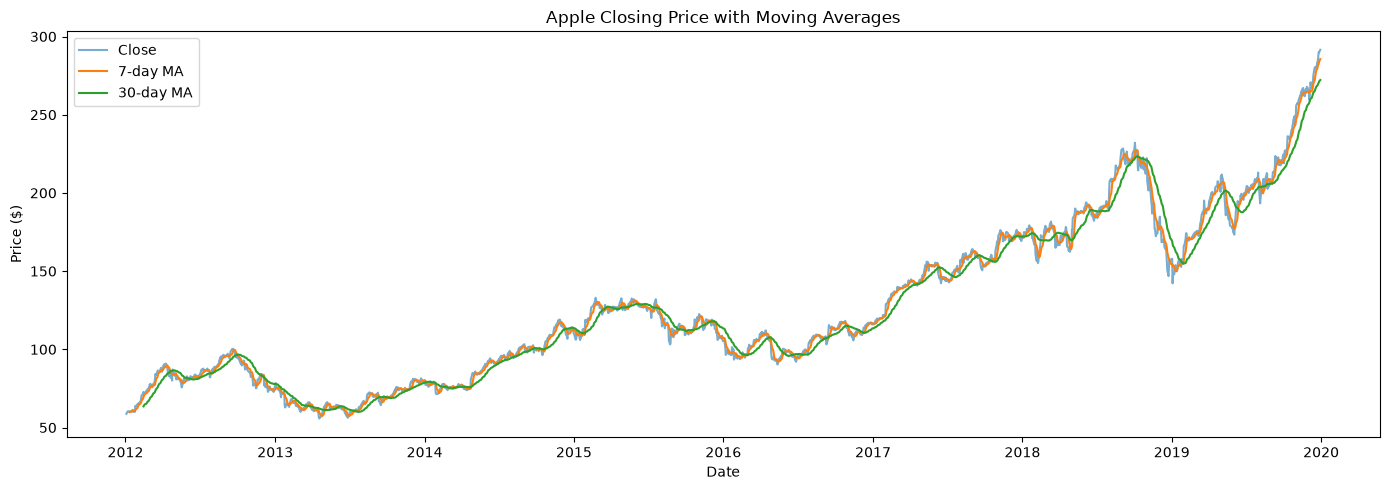

In [22]:
plt.figure(figsize=(14, 5))
plt.plot(data["Date"], data["Close"], label="Close", alpha=0.6)
plt.plot(data["Date"], data["MA_7"], label="7-day MA")
plt.plot(data["Date"], data["MA_30"], label="30-day MA")
plt.title("Apple Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.tight_layout()
plt.show()


This visualization compares the actual closing price with smoothed price series. The 7-day average responds more quickly to recent changes, while the 30-day average is smoother.


### ● Create a daily price range feature.

In [23]:
data["Price_Range"] = data["High"] - data["Low"]
data[["Date", "High", "Low", "Price_Range"]].head()

,Date,High,Low,Price_Range
0,2012-01-03,58.928570,58.428570,0.500000
1,2012-01-04,59.240002,58.468571,0.771431
2,2012-01-05,59.792858,58.952858,0.840000
3,2012-01-06,60.392857,59.888573,0.504284
4,2012-01-09,61.107143,60.192856,0.914287


`Price_Range` is the difference between the day's highest and lowest prices. It represents the intraday range and can provide information about daily price movement.


### ● Create lag features for historical closing prices.

In [24]:
data["Close_Lag_1"] = data["Close"].shift(1)
data["Close_Lag_7"] = data["Close"].shift(7)

data[["Date", "Close", "Close_Lag_1", "Close_Lag_7"]].head(12)

,Date,Close,Close_Lag_1,Close_Lag_7
0,2012-01-03,58.747143,NaN,NaN
1,2012-01-04,59.062859,58.747143,NaN
2,2012-01-05,59.718571,59.062859,NaN
3,2012-01-06,60.342857,59.718571,NaN
4,2012-01-09,60.247143,60.342857,NaN
5,2012-01-10,60.462856,60.247143,NaN
6,2012-01-11,60.364285,60.462856,NaN
7,2012-01-12,60.198570,60.364285,58.747143
8,2012-01-13,59.972858,60.198570,59.062859
9,2012-01-17,60.671429,59.972858,59.718571


`Close_Lag_1` stores the previous trading observation's closing price, and `Close_Lag_7` stores the closing price from seven trading observations earlier. Lag features provide historical context for forecasting.


 ### ● Calculate the percentage change in trading volume.

In [25]:
data["Volume_Change"] = data["Volume"].pct_change()
data[["Date", "Volume", "Volume_Change"]].head(10)

,Date,Volume,Volume_Change
0,2012-01-03,75555200,NaN
1,2012-01-04,65005500,-0.139629
2,2012-01-05,67817400,0.043256
3,2012-01-06,79573200,0.173345
4,2012-01-09,98506100,0.237931
5,2012-01-10,64549100,-0.344720
6,2012-01-11,53771200,-0.166972
7,2012-01-12,53146800,-0.011612
8,2012-01-13,56505400,0.063195
9,2012-01-17,60724300,0.074664


`Volume_Change` measures the proportional change in trading volume from the previous observation. The first value is missing because no previous volume is available.


### ● Review all engineered features.


In [26]:
print("Updated shape:", data.shape)
print("\nColumns:")
print(data.columns.tolist())

data[[
    "Date", "Close", "Daily_Return", "MA_7", "MA_30",
    "Volatility_20", "Price_Range", "Close_Lag_1",
    "Close_Lag_7", "Volume_Change"
]].tail(10)


Updated shape: (2011, 15)

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Daily_Return', 'Volatility_20', 'MA_7', 'MA_30', 'Price_Range', 'Close_Lag_1', 'Close_Lag_7', 'Volume_Change']


,Date,Close,Daily_Return,MA_7,MA_30,Volatility_20,Price_Range,Close_Lag_1,Close_Lag_7,Volume_Change
2001,2019-12-16,279.859985,0.017118,271.907139,264.962334,0.011492,3.809998,275.149994,265.579987,-0.040435
2002,2019-12-17,280.410004,0.001965,273.292855,265.726001,0.011479,2.970001,279.859985,270.709991,-0.109432
2003,2019-12-18,279.739990,-0.002389,275.124281,266.479667,0.011463,2.779999,280.410004,266.920013,0.016381
2004,2019-12-19,280.019989,0.001001,276.772849,267.239000,0.010979,2.229981,279.739990,268.480011,-0.152197
2005,2019-12-20,279.440002,-0.002071,278.011422,267.906001,0.010904,4.089996,280.019989,270.769989,1.805533
2006,2019-12-23,284.000000,0.016318,279.802852,268.701334,0.011232,3.880005,279.440002,271.459991,-0.642827
2007,2019-12-24,284.269989,0.000951,281.105708,269.436999,0.010795,1.970002,284.000000,275.149994,-0.508189
2008,2019-12-26,289.910004,0.019840,282.541425,270.368667,0.011062,5.279999,284.269989,279.859985,0.920864
2009,2019-12-27,289.799988,-0.000379,283.882852,271.212999,0.010918,5.850006,289.910004,280.410004,0.570706
2010,2019-12-30,291.519989,0.005935,285.565709,272.175665,0.010826,7.470001,289.799988,279.739990,-0.014710


The dataset now includes daily returns, moving averages, rolling volatility, intraday price range, lagged closing prices, and volume change. These features summarize different aspects of recent historical behavior.


 ## 7. Handle Missing Values Created by Feature Engineering

### ● Inspect missing values in the engineered dataset.


In [27]:
data.isnull().sum()

Date              0
Open              0
High              0
Low               0
Close             0
Adj Close         0
Volume            0
Daily_Return      1
Volatility_20    20
MA_7              6
MA_30            29
Price_Range       0
Close_Lag_1       1
Close_Lag_7       7
Volume_Change     1
dtype: int64

The rolling calculations and lag features introduce missing values at the beginning of the dataset. These values are expected because the required historical window is not available for the earliest observations.


### ● Create a modeling-ready copy by dropping rows with incomplete engineered features.

In [28]:
data_model = data.dropna().copy()

print("Rows before dropping incomplete feature rows:", len(data))
print("Rows after dropping incomplete feature rows:", len(data_model))
print("Missing values remaining:", data_model.isnull().sum().sum())

data_model.head()

Rows before dropping incomplete feature rows: 2011
Rows after dropping incomplete feature rows: 1982
Missing values remaining: 0


,Date,Open,High,Low,Close,Adj Close,Volume,Daily_Return,Volatility_20,MA_7,MA_30,Price_Range,Close_Lag_1,Close_Lag_7,Volume_Change
29,2012-02-14,72.094284,72.794289,71.714287,72.779999,62.892056,115099600,0.013649,0.017387,69.553674,63.574667,1.080002,71.800003,65.668571,-0.109853
30,2012-02-15,73.465714,75.184288,70.984283,71.095711,61.436600,376530000,-0.023142,0.018831,70.241429,63.986286,4.200005,72.779999,66.281425,2.271341
31,2012-02-16,70.214287,72.127144,69.518570,71.744286,61.997032,236138000,0.009123,0.018661,70.922653,64.409000,2.608574,71.095711,66.975716,-0.372857
32,2012-02-17,71.872856,72.538574,71.471428,71.731430,61.985954,133951300,-0.000179,0.017792,71.441837,64.809428,1.067146,71.744286,68.097145,-0.432741
33,2012-02-21,72.411430,73.550003,72.017143,73.550003,63.557446,151398800,0.025353,0.018085,71.884286,65.249667,1.532860,71.731430,70.452858,0.130253


A separate `df_model` copy is created so the original EDA dataset remains available. With a 30-observation moving average and the specified lag features, the initial incomplete rows are removed. The remaining row count depends on the data and feature windows.


## 8. Model Building and Evaluation

In this stage, we will develop and evaluate suitable time-series forecasting and machine learning models to predict Apple's stock closing prices for the next 30 days.

We will experiment with different models, compare their predictive performance using evaluation metrics, and select the best-performing model for the project.

The objective is to identify a model that provides reliable stock price forecasts using historical data.

In [29]:
print(data_model.head())
print(data_model.shape)
print(data_model.columns)
print(data_model.isnull().sum())

         Date       Open       High        Low      Close  Adj Close  \
29 2012-02-14  72.094284  72.794289  71.714287  72.779999  62.892056   
30 2012-02-15  73.465714  75.184288  70.984283  71.095711  61.436600   
31 2012-02-16  70.214287  72.127144  69.518570  71.744286  61.997032   
32 2012-02-17  71.872856  72.538574  71.471428  71.731430  61.985954   
33 2012-02-21  72.411430  73.550003  72.017143  73.550003  63.557446   

       Volume  Daily_Return  Volatility_20       MA_7      MA_30  Price_Range  \
29  115099600      0.013649       0.017387  69.553674  63.574667     1.080002   
30  376530000     -0.023142       0.018831  70.241429  63.986286     4.200005   
31  236138000      0.009123       0.018661  70.922653  64.409000     2.608574   
32  133951300     -0.000179       0.017792  71.441837  64.809428     1.067146   
33  151398800      0.025353       0.018085  71.884286  65.249667     1.532860   

    Close_Lag_1  Close_Lag_7  Volume_Change  
29    71.800003    65.668571      

In [30]:
data_model['Date'] = pd.to_datetime(data_model['Date'])

data_model = data_model.sort_values('Date').reset_index(drop=True)

print("Start Date:", data_model['Date'].min())
print("End Date:", data_model['Date'].max())
print("Dataset Shape:", data_model.shape)
print("Date Data Type:", data_model['Date'].dtype)

Start Date: 2012-02-14 00:00:00
End Date: 2019-12-30 00:00:00
Dataset Shape: (1982, 15)
Date Data Type: datetime64[ns]


## 9. Model Preparation

The prepared dataset contains historical stock prices and engineered features. The closing price (`Close`) is selected as the target variable for forecasting.

The dataset will be divided into training and testing sets while maintaining chronological order to ensure that future observations are not used to predict past stock prices.

In [31]:
target = 'Close'

features = data_model.drop(columns=['Date', target])

print("Target:", target)
print("Features:", features.columns.tolist())
print("Number of Features:", len(features.columns))

Target: Close
Features: ['Open', 'High', 'Low', 'Adj Close', 'Volume', 'Daily_Return', 'Volatility_20', 'MA_7', 'MA_30', 'Price_Range', 'Close_Lag_1', 'Close_Lag_7', 'Volume_Change']
Number of Features: 13


## 10. Training and Testing Data

The dataset is divided chronologically into training and testing sets. The earlier observations are used to train the models, while the final 30 trading days are reserved for testing.

This approach evaluates how effectively the models forecast stock prices using historical information without randomly shuffling the time-series data.

## 11. Creating Features for Forecasting

For future stock price prediction, the models must rely on information available from previous trading days. Therefore, historical closing prices are used to create lag features and moving averages.

These features help the models identify recent price movements and longer-term trends while avoiding the use of unavailable future information.

In [32]:
model_data = data_model[['Date', 'Close']].copy()

model_data['Lag_1'] = model_data['Close'].shift(1)
model_data['Lag_2'] = model_data['Close'].shift(2)
model_data['Lag_3'] = model_data['Close'].shift(3)
model_data['Lag_7'] = model_data['Close'].shift(7)
model_data['Lag_14'] = model_data['Close'].shift(14)
model_data['Lag_30'] = model_data['Close'].shift(30)

model_data['MA_7'] = model_data['Close'].shift(1).rolling(7).mean()
model_data['MA_30'] = model_data['Close'].shift(1).rolling(30).mean()

model_data = model_data.dropna().reset_index(drop=True)

print("Dataset Shape:", model_data.shape)
display(model_data.head())

Dataset Shape: (1952, 10)


,Date,Close,Lag_1,Lag_2,Lag_3,Lag_7,Lag_14,Lag_30,MA_7,MA_30
0,2012-03-28,88.231430,87.782860,86.711426,85.150002,85.871429,77.427139,72.779999,86.253265,78.856667
1,2012-03-29,87.122856,88.231430,87.782860,86.711426,86.565712,77.881432,71.095711,86.590408,79.371714
2,2012-03-30,85.650002,87.122856,88.231430,87.782860,86.071426,78.857140,71.744286,86.670000,79.905953
3,2012-04-02,88.375717,85.650002,87.122856,88.231430,85.620003,81.157143,71.731430,86.609797,80.369476
4,2012-04-03,89.902855,88.375717,85.650002,87.122856,85.150002,84.225716,73.550003,87.003470,80.924286


## 12. Splitting Training and Testing Data

The prepared dataset is divided into training and testing sets based on chronological order. The earlier observations are used to train the forecasting models, while the final 30 trading days are reserved for evaluating their prediction performance.

In [33]:
train_data = model_data.iloc[:-30]
test_data = model_data.iloc[-30:]

X_train = train_data.drop(columns=['Date', 'Close'])
y_train = train_data['Close']

X_test = test_data.drop(columns=['Date', 'Close'])
y_test = test_data['Close']

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Period:", train_data['Date'].min(), "to", train_data['Date'].max())
print("Testing Period:", test_data['Date'].min(), "to", test_data['Date'].max())

Training Data: (1922, 8)
Testing Data: (30, 8)
Training Period: 2012-03-28 00:00:00 to 2019-11-14 00:00:00
Testing Period: 2019-11-15 00:00:00 to 2019-12-30 00:00:00


In [34]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [35]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


## 13. Baseline Model

A baseline model is created to establish a reference point for evaluating the performance of more advanced forecasting models.

In this approach, the previous trading day's closing price is used as the predicted closing price for the next trading day.

In [36]:
baseline_predictions = test_data['Lag_1'].values

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_mape = np.mean(np.abs((y_test - baseline_predictions) / y_test)) * 100

print("Baseline Model Performance")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("MAPE:", baseline_mape)

Baseline Model Performance
MAE: 2.3586639333333417
RMSE: 2.9140787586226446
MAPE: 0.8698456959916634


In [37]:
baseline_30 = np.repeat(y_train.iloc[-1], len(y_test))

baseline_30_mae = mean_absolute_error(y_test, baseline_30)
baseline_30_rmse = np.sqrt(mean_squared_error(y_test, baseline_30))
baseline_30_mape = np.mean(np.abs((y_test - baseline_30) / y_test)) * 100

print("30-Day Baseline Performance")
print("MAE:", baseline_30_mae)
print("RMSE:", baseline_30_rmse)
print("MAPE:", baseline_30_mape)

30-Day Baseline Performance
MAE: 9.907653533333331
RMSE: 13.263580397804052
MAPE: 3.537800485478377


## 14. ARIMA Model

ARIMA (AutoRegressive Integrated Moving Average) is a statistical time-series forecasting model used to predict future stock prices based on historical observations.

In this project, ARIMA is used to forecast Apple's closing stock prices for the next 30 trading days using historical closing-price data.

The model consists of three main parameters:

- **AR (p):** Uses previous observations to predict future values.
- **I (d):** Applies differencing to make the time series stationary.
- **MA (q):** Uses previous forecasting errors to improve predictions.

The model will be trained using historical closing prices and evaluated against the actual stock prices from the testing period.

### 14.1 Stationarity Test

Before fitting the ARIMA model, the stationarity of the closing-price series is examined using the Augmented Dickey-Fuller (ADF) test.

This test helps determine whether differencing is required to make the time series stationary.

In [38]:
from statsmodels.tsa.stattools import adfuller

close_prices = train_data['Close']

adf_result = adfuller(close_prices)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] <= 0.05:
    print("The series is stationary.")
else:
    print("The series is non-stationary.")

ADF Statistic: 0.8104210250878151
p-value: 0.9918025341885387
The series is non-stationary.


### 14.2 Applying Differencing

Since the original closing-price series is non-stationary, first-order differencing is applied to remove the trend.

Differencing calculates the difference between consecutive observations. The ADF test is then performed again to check whether the transformed series has become stationary.

In [39]:
close_diff = close_prices.diff().dropna()

adf_diff = adfuller(close_diff)

print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

if adf_diff[1] <= 0.05:
    print("The differenced series is stationary.")
else:
    print("The differenced series is non-stationary.")

ADF Statistic: -13.536603807463726
p-value: 2.560470833157715e-25
The differenced series is stationary.


### 14.3 Identifying ARIMA Parameters

After achieving stationarity through first-order differencing, the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots are used to identify suitable autoregressive (p) and moving average (q) parameters.

These plots help understand the correlation between observations at different time lags and guide the selection of ARIMA model parameters.

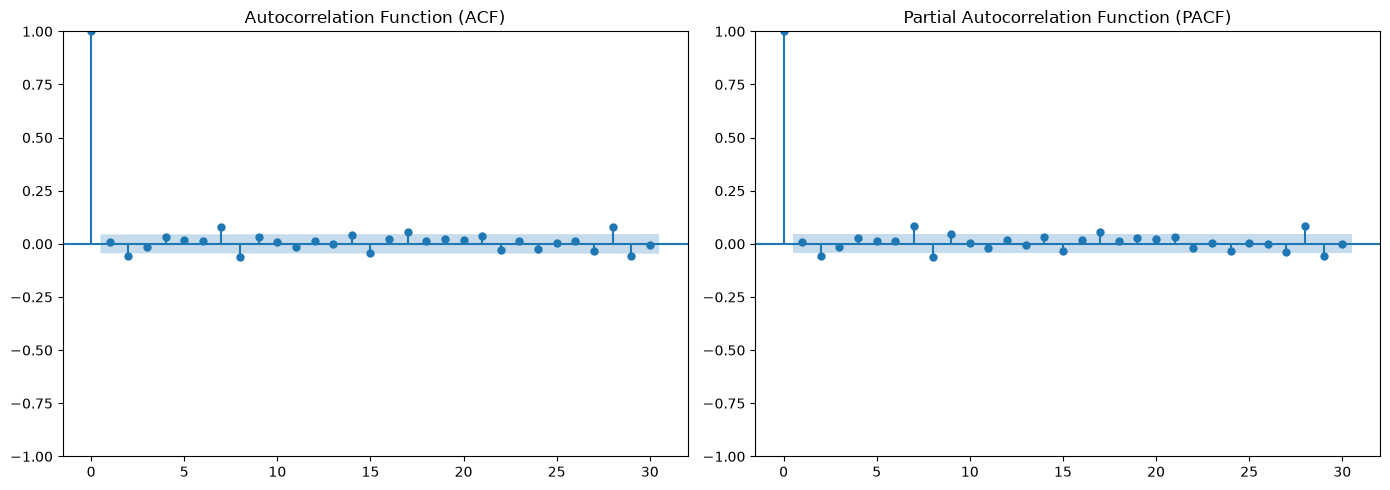

In [40]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(close_diff, lags=30, ax=axes[0])
axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(close_diff, lags=30, method='ywm', ax=axes[1])
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

### 14.4 ARIMA Parameter Selection

The ACF and PACF plots provide an initial understanding of the autocorrelation patterns in the differenced series. Since the plots do not show a clear cutoff, different combinations of ARIMA parameters are evaluated using the Akaike Information Criterion (AIC).

The parameter combination with the lowest AIC is selected for building the ARIMA model.

In [41]:
import warnings
warnings.filterwarnings("ignore")

results = []

for p in range(4):
    for q in range(4):
        try:
            model = ARIMA(close_prices, order=(p, 1, q))
            fitted_model = model.fit()

            results.append({
                'p': p,
                'd': 1,
                'q': q,
                'AIC': fitted_model.aic
            })

        except:
            continue

arima_results = pd.DataFrame(results)
arima_results = arima_results.sort_values('AIC')

display(arima_results)

,p,d,q,AIC
7,1,1,3,8371.708169
11,2,1,3,8372.185622
14,3,1,2,8372.495662
8,2,1,0,8372.904789
2,0,1,2,8373.326488
12,3,1,0,8374.528356
9,2,1,1,8374.728998
15,3,1,3,8374.838654
3,0,1,3,8374.990192
6,1,1,2,8375.187233


### 14.5 ARIMA Model Training and Forecasting

Based on the AIC comparison, the ARIMA(1,1,3) configuration is selected for forecasting.

The model is trained using the historical closing prices from the training dataset. It then generates predictions for the next 30 trading days, which are compared with the actual closing prices in the testing dataset.

In [42]:
arima_model = ARIMA(y_train, order=(1, 1, 3))

arima_fitted = arima_model.fit()

arima_predictions = arima_fitted.forecast(steps=30)

arima_mae = mean_absolute_error(y_test, arima_predictions)
arima_rmse = np.sqrt(mean_squared_error(y_test, arima_predictions))
arima_mape = np.mean(np.abs((y_test - arima_predictions) / y_test)) * 100

print("ARIMA(1,1,3) Performance")
print("MAE:", arima_mae)
print("RMSE:", arima_rmse)
print("MAPE:", arima_mape)

ARIMA(1,1,3) Performance
MAE: 7.586865442838839
RMSE: 10.465059441989682
MAPE: 2.707573690153988


### 14.6 Actual vs Predicted Stock Prices

The actual closing prices are compared with the predicted closing prices generated by the ARIMA model.

This visualization helps evaluate how closely the model follows the actual stock price movements during the testing period.

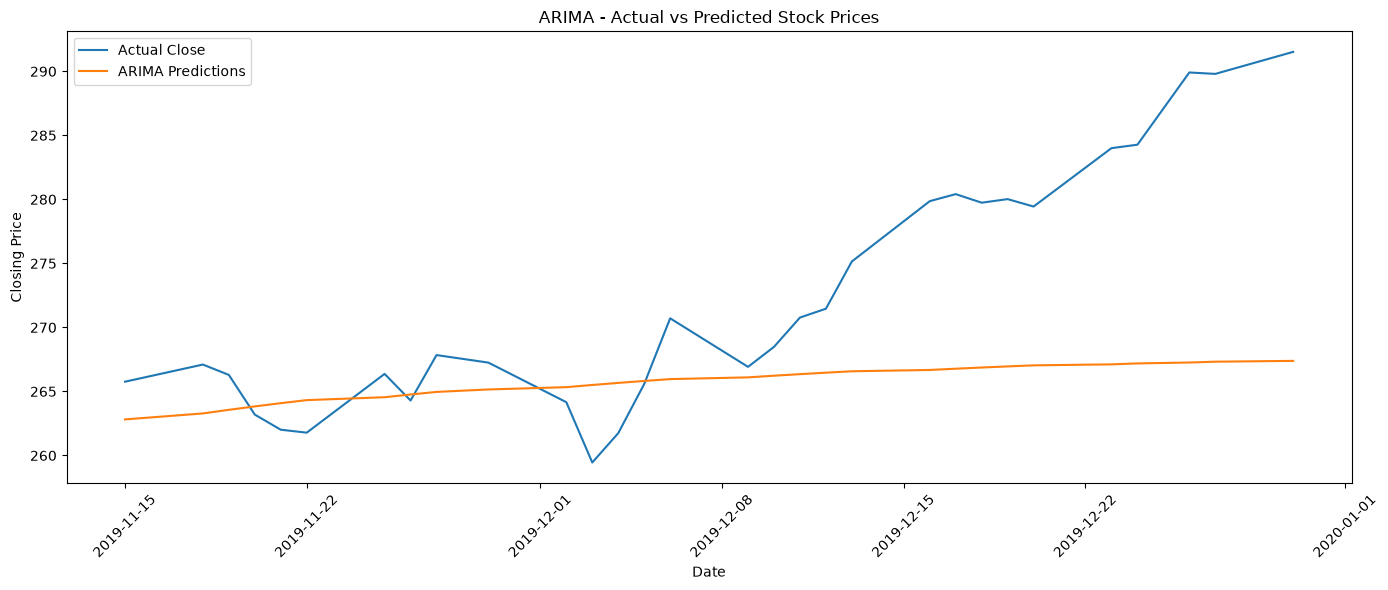

In [43]:
plt.figure(figsize=(14, 6))

plt.plot(test_data['Date'], y_test.values, label='Actual Close')
plt.plot(test_data['Date'], np.array(arima_predictions), label='ARIMA Predictions')

plt.title('ARIMA - Actual vs Predicted Stock Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 14.7 ARIMA Model Conclusion

The ARIMA(1,1,3) model was successfully trained and evaluated using historical Apple stock prices.

The model achieved a MAE of 7.5869, RMSE of 10.4651, and MAPE of 2.7076%.

The actual vs predicted visualization shows that the model captures the general price level but struggles to follow significant upward movements in the stock price.

Although ARIMA performed better than the baseline model, further evaluation with other forecasting and machine learning models is required to identify the most suitable model for this project.

## 15. SARIMA Model

SARIMA (Seasonal AutoRegressive Integrated Moving Average) is an extension of the ARIMA model that considers both non-seasonal and seasonal patterns in time-series data.

In this project, SARIMA is used to forecast Apple's closing stock prices for the next 30 trading days by considering historical price movements and possible recurring patterns.

The model consists of two sets of parameters:

- **Non-seasonal parameters (p, d, q):** Capture the general trend and autocorrelation in the time series.
- **Seasonal parameters (P, D, Q, s):** Capture recurring seasonal patterns in the data.

SARIMA will be trained and evaluated using the same historical training period and 30-day testing period used for ARIMA.

### 15.1 Seasonal Parameter Selection

SARIMA extends the ARIMA model by incorporating seasonal components to identify recurring patterns in time-series data.

For this analysis, an initial seasonal period of five trading days is considered to investigate possible weekly patterns in Apple's stock prices.

Different combinations of seasonal parameters are evaluated using the Akaike Information Criterion (AIC). The configuration with the lowest AIC is selected for further model evaluation.

In [44]:
seasonal_results = []

for P in range(2):
    for D in range(2):
        for Q in range(2):
            try:
                model = SARIMAX(
                    y_train,
                    order=(1, 1, 3),
                    seasonal_order=(P, D, Q, 5),
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )

                fitted = model.fit(disp=False)

                seasonal_results.append({
                    'P': P,
                    'D': D,
                    'Q': Q,
                    's': 5,
                    'AIC': fitted.aic
                })

            except Exception:
                continue

sarima_results = pd.DataFrame(seasonal_results)
sarima_results = sarima_results.sort_values('AIC')

display(sarima_results)

,P,D,Q,s,AIC
1,0,0,1,5,8340.154642
5,1,0,1,5,8340.841716
3,0,1,1,5,8342.780008
7,1,1,1,5,8344.313982
4,1,0,0,5,8351.119536
0,0,0,0,5,8358.965831
6,1,1,0,5,9071.330737
2,0,1,0,5,9215.202239


### 15.2 SARIMA Model Training and Forecasting

Based on the AIC comparison, the SARIMA(1,1,3)(0,0,1,5) configuration is selected for forecasting.

The model is trained using historical Apple closing prices from the training dataset. It generates forecasts for the next 30 trading days, which are compared with the actual closing prices in the testing dataset.

In [45]:
sarima_model = SARIMAX(
    y_train,
    order=(1, 1, 3),
    seasonal_order=(0, 0, 1, 5),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fitted = sarima_model.fit(disp=False)

sarima_predictions = sarima_fitted.forecast(steps=30)

sarima_mae = mean_absolute_error(y_test, sarima_predictions)
sarima_rmse = np.sqrt(mean_squared_error(y_test, sarima_predictions))
sarima_mape = np.mean(np.abs((y_test - sarima_predictions) / y_test)) * 100

print("SARIMA Model Performance")
print("MAE:", sarima_mae)
print("RMSE:", sarima_rmse)
print("MAPE:", sarima_mape)

SARIMA Model Performance
MAE: 8.041091394138508
RMSE: 11.080903373453442
MAPE: 2.86866512828229


### 15.3 Actual vs Predicted Stock Prices

The actual closing prices are compared with the 30-day forecasts generated by the SARIMA model.

This visualization helps assess how closely the SARIMA model follows the actual stock price movements during the testing period.

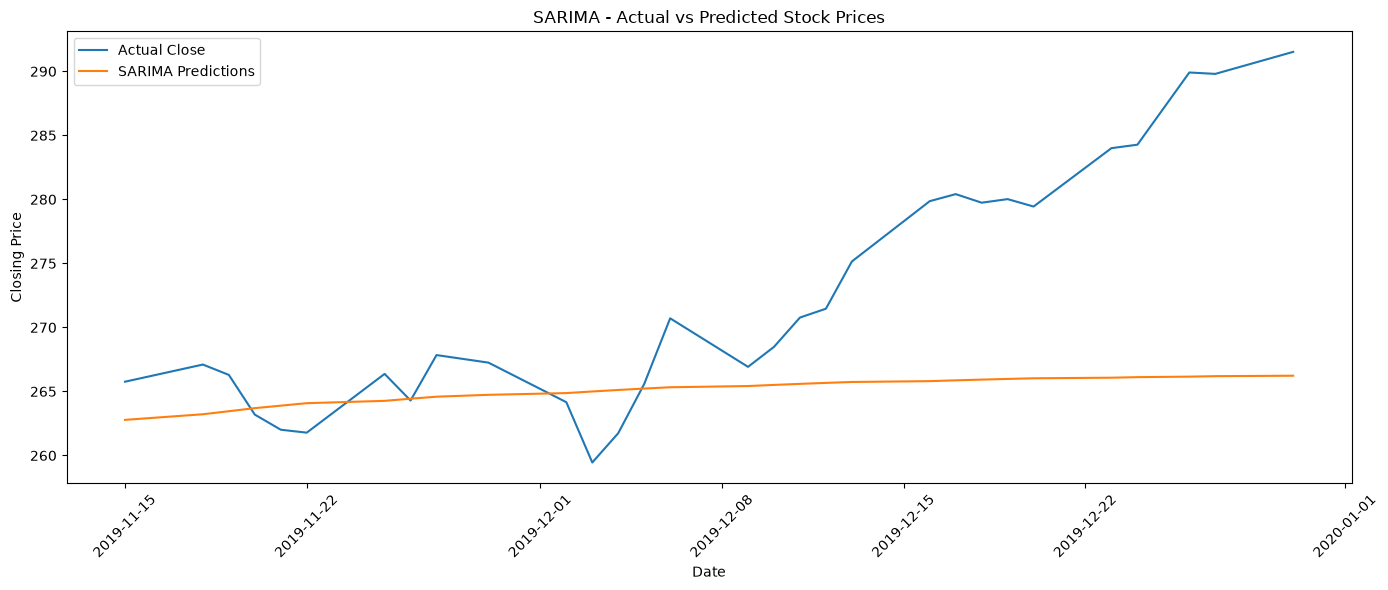

In [46]:
plt.figure(figsize=(14, 6))

plt.plot(test_data['Date'], y_test.values, label='Actual Close')
plt.plot(test_data['Date'], np.array(sarima_predictions), label='SARIMA Predictions')

plt.title('SARIMA - Actual vs Predicted Stock Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 15.4 SARIMA Model Conclusion

The SARIMA(1,1,3)(0,0,1,5) model was successfully trained and evaluated using historical Apple stock prices.

The model achieved a MAE of 8.0411, RMSE of 11.0809, and MAPE of 2.8687%.

The actual vs predicted visualization shows that the model produces relatively smooth forecasts but struggles to capture significant upward movements in stock prices.

Compared with ARIMA, SARIMA produced slightly higher errors across all three evaluation metrics. Further evaluation with machine learning models is required to identify the most suitable forecasting model for this project.

## 16. Random Forest Regression Model

Random Forest is a supervised machine learning algorithm that combines multiple decision trees to generate predictions.

Each decision tree makes its own prediction, and the final output is calculated by combining the predictions from all the trees.

In this project, Random Forest Regression is used to predict Apple's future closing stock prices using historical price information, lag features, and moving averages.

The model is trained using historical observations and evaluated by forecasting the next 30 trading days.

### 16.1 Random Forest Model Training and Forecasting

The Random Forest Regressor is trained using historical closing prices and their corresponding lag and moving-average features.

A recursive forecasting approach is used to predict the next 30 trading days. Each predicted closing price is added to the historical sequence and used to generate the features required for the next prediction.

In [47]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_train)

history = list(y_train.values)
rf_predictions = []

for i in range(30):
    row = {
        'Lag_1': history[-1],
        'Lag_2': history[-2],
        'Lag_3': history[-3],
        'Lag_7': history[-7],
        'Lag_14': history[-14],
        'Lag_30': history[-30],
        'MA_7': np.mean(history[-7:]),
        'MA_30': np.mean(history[-30:])
    }

    input_data = pd.DataFrame([row], columns=X_train.columns)

    prediction = rf_model.predict(input_data)[0]

    rf_predictions.append(prediction)
    history.append(prediction)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_mape = np.mean(np.abs((y_test.values - rf_predictions) / y_test.values)) * 100

print("Random Forest Model Performance")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("MAPE:", rf_mape)

Random Forest Model Performance
MAE: 10.259780663683332
RMSE: 13.611789611353577
MAPE: 3.665425238283323


### 16.2 Actual vs Predicted Stock Prices

The actual closing prices are compared with the 30-day forecasts generated by the Random Forest model.

This visualization helps evaluate how closely the model follows the actual stock price movements during the testing period.

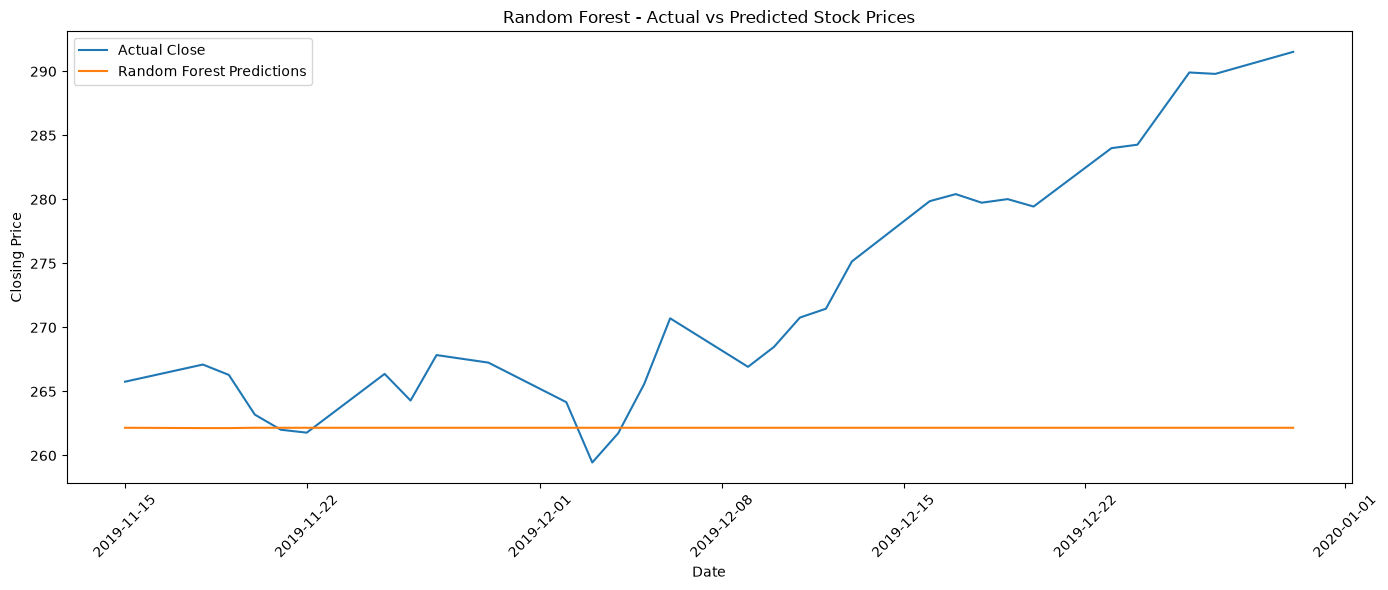

In [48]:
plt.figure(figsize=(14, 6))

plt.plot(test_data['Date'], y_test.values, label='Actual Close')
plt.plot(test_data['Date'], rf_predictions, label='Random Forest Predictions')

plt.title('Random Forest - Actual vs Predicted Stock Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 16.3 Random Forest Model Conclusion

The Random Forest Regressor was successfully trained using historical stock prices and engineered features.

The model achieved a MAE of 10.2598, RMSE of 13.6118, and MAPE of 3.6654%.

The actual vs predicted visualization shows that the model produces nearly constant predictions during recursive forecasting and fails to capture the upward movement in Apple's stock prices.

Compared with the baseline, ARIMA, and SARIMA models, Random Forest produced higher prediction errors. Therefore, its performance was comparatively weaker in this forecasting experiment.

## 17. XGBoost Regression Model

XGBoost (Extreme Gradient Boosting) is an advanced machine learning algorithm based on gradient-boosted decision trees.

It builds multiple decision trees sequentially, where each new tree attempts to reduce the errors made by the previous trees.

In this project, XGBoost Regression is used to predict Apple's future closing stock prices using historical closing prices, lag features, and moving averages.

The model is trained using historical observations and evaluated by forecasting the next 30 trading days.

### 17.1 XGBoost Model Training and Forecasting

The XGBoost Regressor is trained using historical closing prices and engineered lag and moving-average features.

A recursive forecasting approach is used to predict the next 30 trading days. Each predicted closing price is added to the historical sequence and used to calculate the features required for the following prediction.

In [49]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    colsample_bytree=0.9,
    objective='reg:squarederror',
    random_state=42
)

xgb_model.fit(X_train, y_train)

history = list(y_train.values)
xgb_predictions = []

for i in range(30):
    row = {
        'Lag_1': history[-1],
        'Lag_2': history[-2],
        'Lag_3': history[-3],
        'Lag_7': history[-7],
        'Lag_14': history[-14],
        'Lag_30': history[-30],
        'MA_7': np.mean(history[-7:]),
        'MA_30': np.mean(history[-30:])
    }

    input_data = pd.DataFrame([row], columns=X_train.columns)

    prediction = xgb_model.predict(input_data)[0]

    xgb_predictions.append(prediction)
    history.append(prediction)

xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_mape = np.mean(np.abs((y_test.values - xgb_predictions) / y_test.values)) * 100

print("XGBoost Model Performance")
print("MAE:", xgb_mae)
print("RMSE:", xgb_rmse)
print("MAPE:", xgb_mape)

XGBoost Model Performance
MAE: 10.651412961132813
RMSE: 13.980543286376577
MAPE: 3.807893446763741


### 17.2 Actual vs Predicted Stock Prices

The actual closing prices are compared with the 30-day forecasts generated by the XGBoost model.

This visualization helps evaluate how closely the model follows the actual stock price movements during the testing period.

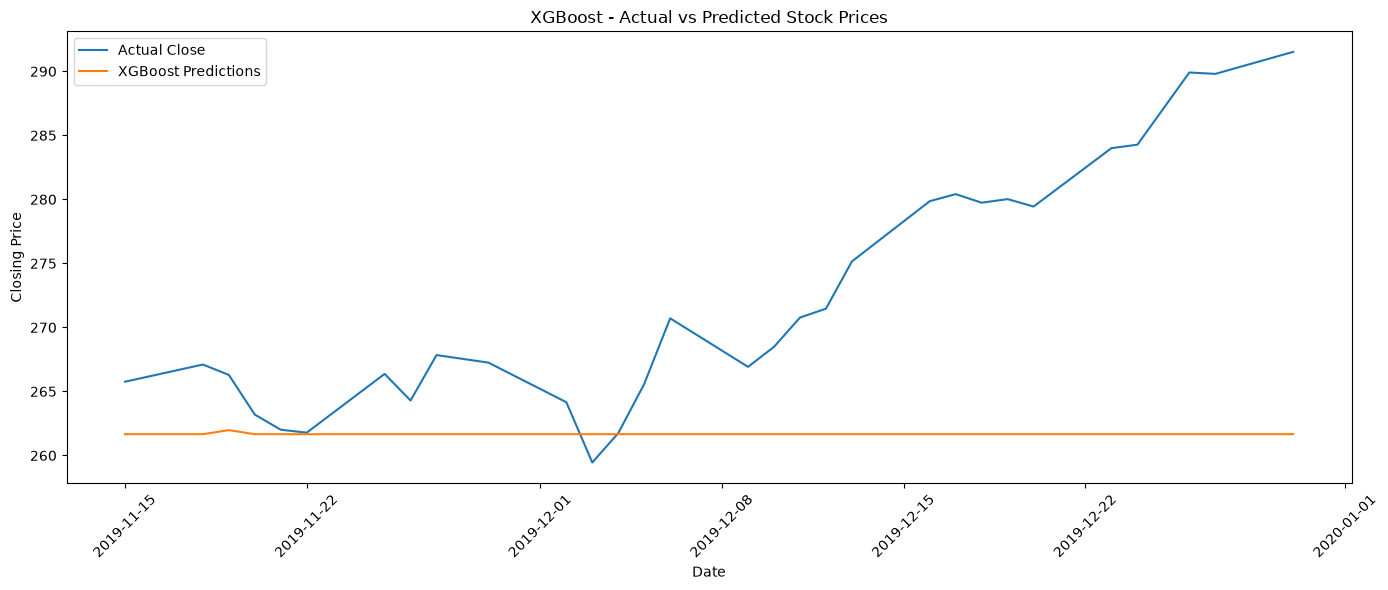

In [50]:
plt.figure(figsize=(14, 6))

plt.plot(test_data['Date'], y_test.values, label='Actual Close')
plt.plot(test_data['Date'], xgb_predictions, label='XGBoost Predictions')

plt.title('XGBoost - Actual vs Predicted Stock Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 17.3 XGBoost Model Conclusion

The XGBoost Regressor was successfully trained using historical stock prices and engineered features.

The model achieved a MAE of 10.9383, RMSE of 14.2158, and MAPE of 3.9130%.

The actual vs predicted visualization shows that the model produces nearly constant predictions during recursive forecasting and struggles to capture the upward movement in Apple's stock prices.

Compared with the baseline, ARIMA, SARIMA, and Random Forest models, XGBoost produced the highest prediction errors in this experiment.

## 18. Walk-Forward Validation

Walk-forward validation is used to evaluate forecasting models across multiple chronological periods. Instead of evaluating a model on only one test period, the training window is progressively expanded, and the model forecasts the next 30 trading days in each validation period.

This approach helps assess how consistently the models perform across different market conditions. The final 30 trading days will remain separate as the holdout test set and will not be used during validation.

### 18.1 Preparing the Walk-Forward Validation

The available training data will be divided into multiple chronological validation periods. Each validation period will contain 30 trading days, while the training window will expand as we move forward through time.

The final 30 trading days reserved for testing will be excluded from this validation process to prevent data leakage.

In [51]:
validation_data = model_data.iloc[:-30].copy()

initial_train_size = int(len(validation_data) * 0.70)
validation_window = 30

validation_splits = []

for start in range(initial_train_size, len(validation_data) - validation_window + 1, validation_window):
    train_fold = validation_data.iloc[:start]
    val_fold = validation_data.iloc[start:start + validation_window]

    validation_splits.append((train_fold, val_fold))

print("Number of validation folds:", len(validation_splits))

for i, (train_fold, val_fold) in enumerate(validation_splits, 1):
    print(
        f"Fold {i}: Training rows = {len(train_fold)}, "
        f"Validation rows = {len(val_fold)}"
    )

Number of validation folds: 19
Fold 1: Training rows = 1345, Validation rows = 30
Fold 2: Training rows = 1375, Validation rows = 30
Fold 3: Training rows = 1405, Validation rows = 30
Fold 4: Training rows = 1435, Validation rows = 30
Fold 5: Training rows = 1465, Validation rows = 30
Fold 6: Training rows = 1495, Validation rows = 30
Fold 7: Training rows = 1525, Validation rows = 30
Fold 8: Training rows = 1555, Validation rows = 30
Fold 9: Training rows = 1585, Validation rows = 30
Fold 10: Training rows = 1615, Validation rows = 30
Fold 11: Training rows = 1645, Validation rows = 30
Fold 12: Training rows = 1675, Validation rows = 30
Fold 13: Training rows = 1705, Validation rows = 30
Fold 14: Training rows = 1735, Validation rows = 30
Fold 15: Training rows = 1765, Validation rows = 30
Fold 16: Training rows = 1795, Validation rows = 30
Fold 17: Training rows = 1825, Validation rows = 30
Fold 18: Training rows = 1855, Validation rows = 30
Fold 19: Training rows = 1885, Validation 

### 18.2 Hyperparameter Tuning

Hyperparameter tuning is performed to identify suitable model configurations that improve forecasting performance.

Random Forest and XGBoost models are tuned using chronological validation periods to identify parameter combinations that minimize forecasting errors. The final 30 trading days remain reserved for independent testing.

In [52]:
rf_parameter_sets = [
    {'n_estimators': 200, 'max_depth': 8, 'min_samples_split': 5, 'min_samples_leaf': 2},
    {'n_estimators': 300, 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 2},
    {'n_estimators': 300, 'max_depth': 12, 'min_samples_split': 5, 'min_samples_leaf': 4}
]

rf_tuning_results = []

for params in rf_parameter_sets:
    fold_errors = []

    for train_fold, val_fold in validation_splits:
        X_fold = train_fold.drop(columns=['Date', 'Close'])
        y_fold = train_fold['Close']

        model = RandomForestRegressor(**params, random_state=42)
        model.fit(X_fold, y_fold)

        history = train_fold['Close'].tolist()
        predictions = []

        for _ in range(len(val_fold)):
            features = [
                history[-1],
                history[-2],
                history[-3],
                history[-7],
                history[-14],
                history[-30],
                np.mean(history[-7:]),
                np.mean(history[-30:])
            ]

            prediction = model.predict([features])[0]
            predictions.append(prediction)
            history.append(prediction)

        fold_errors.append(
            mean_absolute_error(val_fold['Close'], predictions)
        )

    rf_tuning_results.append({
        'Parameters': params,
        'Average_MAE': np.mean(fold_errors)
    })

rf_tuning_df = pd.DataFrame(rf_tuning_results)
rf_tuning_df = rf_tuning_df.sort_values('Average_MAE').reset_index(drop=True)

display(rf_tuning_df)

,Parameters,Average_MAE
0,"{'n_estimators': 300, 'max_depth': 12, 'min_sa...",9.322631
1,"{'n_estimators': 300, 'max_depth': 10, 'min_sa...",9.337031
2,"{'n_estimators': 200, 'max_depth': 8, 'min_sam...",9.337271


In [53]:
best_rf_params = rf_tuning_df.iloc[0]['Parameters']

print("Best Random Forest Parameters:")
print(best_rf_params)

Best Random Forest Parameters:
{'n_estimators': 300, 'max_depth': 12, 'min_samples_split': 5, 'min_samples_leaf': 4}


In [54]:
xgb_parameter_sets = [
    {'n_estimators': 300, 'learning_rate': 0.03, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.8},
    {'n_estimators': 500, 'learning_rate': 0.03, 'max_depth': 4, 'subsample': 0.8, 'colsample_bytree': 0.8},
    {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 0.9, 'colsample_bytree': 0.9}
]

xgb_tuning_results = []

for params in xgb_parameter_sets:
    fold_errors = []

    for train_fold, val_fold in validation_splits:
        X_fold = train_fold.drop(columns=['Date', 'Close'])
        y_fold = train_fold['Close']

        model = xgb.XGBRegressor(
            **params,
            objective='reg:squarederror',
            random_state=42
        )
        model.fit(X_fold, y_fold)

        history = train_fold['Close'].tolist()
        predictions = []

        for _ in range(len(val_fold)):
            features = [
                history[-1],
                history[-2],
                history[-3],
                history[-7],
                history[-14],
                history[-30],
                np.mean(history[-7:]),
                np.mean(history[-30:])
            ]

            prediction = model.predict(np.array([features]))[0]
            predictions.append(prediction)
            history.append(prediction)

        fold_errors.append(
            mean_absolute_error(val_fold['Close'], predictions)
        )

    xgb_tuning_results.append({
        'Parameters': params,
        'Average_MAE': np.mean(fold_errors)
    })

xgb_tuning_df = pd.DataFrame(xgb_tuning_results)
xgb_tuning_df = xgb_tuning_df.sort_values('Average_MAE').reset_index(drop=True)

display(xgb_tuning_df)

,Parameters,Average_MAE
0,"{'n_estimators': 300, 'learning_rate': 0.03, '...",9.100648
1,"{'n_estimators': 500, 'learning_rate': 0.03, '...",9.705295
2,"{'n_estimators': 500, 'learning_rate': 0.05, '...",9.749388


In [56]:
best_xgb_params = xgb_tuning_df.iloc[0]['Parameters']

print("Best XGBoost Parameters:")
print(best_xgb_params)

Best XGBoost Parameters:
{'n_estimators': 300, 'learning_rate': 0.03, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.8}


### 18.3 Evaluating Models Across Validation Folds

Each forecasting model will be trained separately on every training fold and evaluated on the following 30 trading days. The evaluation metrics will be recorded for each fold to compare model performance across different time periods.

The models will use recursive forecasting, where each predicted closing price is used to generate the next day's prediction.

In [57]:
arima_validation_results = []

for i, (train_fold, val_fold) in enumerate(validation_splits, 1):
    model = ARIMA(train_fold['Close'], order=(1, 1, 3))
    fitted_model = model.fit()

    predictions = fitted_model.forecast(steps=30)

    actual = val_fold['Close'].values

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    mape = np.mean(np.abs((actual - predictions) / actual)) * 100

    arima_validation_results.append({
        'Fold': i,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

arima_validation_df = pd.DataFrame(arima_validation_results)

print(arima_validation_df)

    Fold        MAE       RMSE       MAPE
0      1   9.873636  10.145626   6.154383
1      2   3.827993   4.462256   2.478258
2      3  14.445161  14.970173   8.404668
3      4   4.789080   5.474381   2.727627
4      5   7.928883  10.290186   4.847258
5      6   4.037070   4.835132   2.353309
6      7  12.071474  12.681150   6.606670
7      8   3.000188   3.684153   1.607117
8      9  13.346822  16.564222   6.318339
9     10   5.638305   6.766467   2.494829
10    11  18.050225  22.073194   9.068613
11    12  11.258323  14.329333   7.207525
12    13  18.862911  21.518221  11.334384
13    14  10.454537  12.973862   5.564681
14    15   7.550876   8.580024   3.717863
15    16   8.139792   8.896580   4.336992
16    17   6.505399   7.345368   3.159355
17    18  12.308418  13.988126   5.698111
18    19  17.804203  21.203358   7.340099


In [58]:
arima_validation_df[['MAE', 'RMSE', 'MAPE']].mean().round(4)

MAE      9.9944
RMSE    11.6201
MAPE     5.3379
dtype: float64

In [59]:
sarima_validation_results = []

for i, (train_fold, val_fold) in enumerate(validation_splits, 1):
    model = SARIMAX(
        train_fold['Close'],
        order=(1, 1, 3),
        seasonal_order=(0, 0, 1, 5),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(disp=False)
    predictions = fitted_model.forecast(steps=30)

    actual = val_fold['Close'].values

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    mape = np.mean(np.abs((actual - predictions) / actual)) * 100

    sarima_validation_results.append({
        'Fold': i,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

sarima_validation_df = pd.DataFrame(sarima_validation_results)

print(sarima_validation_df)

    Fold        MAE       RMSE       MAPE
0      1   9.854215  10.126547   6.142242
1      2   3.811751   4.442215   2.467714
2      3  14.473402  14.997345   8.421211
3      4   4.813126   5.497419   2.741401
4      5   7.936861  10.296933   4.852009
5      6   4.038016   4.836689   2.353889
6      7  12.070947  12.681863   6.606130
7      8   2.996185   3.675258   1.604925
8      9  13.350993  16.567455   6.320393
9     10   5.645814   6.773927   2.498172
10    11  18.083071  22.099758   9.084385
11    12  12.396492  15.694000   7.935626
12    13  17.641093  20.119849  10.600005
13    14   9.834784  12.352053   5.229216
14    15   6.622420   7.636723   3.273626
15    16   8.123814   8.870396   4.327173
16    17   6.095576   6.932487   2.960350
17    18  12.259054  13.936397   5.675122
18    19  17.726504  21.125407   7.307523


In [60]:
sarima_validation_df[['MAE', 'RMSE', 'MAPE']].mean().round(4)

MAE      9.8828
RMSE    11.5086
MAPE     5.2843
dtype: float64

In [61]:
rf_validation_results = []

for i, (train_fold, val_fold) in enumerate(validation_splits, 1):
    X_fold = train_fold.drop(columns=['Date', 'Close'])
    y_fold = train_fold['Close']

    model = RandomForestRegressor(
    **best_rf_params,
    random_state=42
    )

    model.fit(X_fold, y_fold)

    history = list(y_fold.values)
    predictions = []

    for _ in range(30):
        row = {
            'Lag_1': history[-1],
            'Lag_2': history[-2],
            'Lag_3': history[-3],
            'Lag_7': history[-7],
            'Lag_14': history[-14],
            'Lag_30': history[-30],
            'MA_7': np.mean(history[-7:]),
            'MA_30': np.mean(history[-30:])
        }

        input_data = pd.DataFrame([row], columns=X_fold.columns)
        prediction = model.predict(input_data)[0]

        predictions.append(prediction)
        history.append(prediction)

    actual = val_fold['Close'].values

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    mape = np.mean(np.abs((actual - predictions) / actual)) * 100

    rf_validation_results.append({
        'Fold': i,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

rf_validation_df = pd.DataFrame(rf_validation_results)

print(rf_validation_df)

    Fold        MAE       RMSE      MAPE
0      1   9.959583  10.261462  6.207106
1      2   4.601872   5.201627  2.976101
2      3  11.882919  12.433451  6.908223
3      4   3.954135   4.660483  2.250009
4      5   8.122751  10.477289  4.963493
5      6   3.951481   4.714413  2.260279
6      7  12.091868  12.984119  6.581060
7      8   2.971544   3.358471  1.572344
8      9  15.928818  18.969016  7.575072
9     10   8.120117   8.951712  3.605149
10    11  17.623858  21.735271  8.864197
11    12  12.697805  16.074370  8.129143
12    13   8.949832  11.757843  5.294670
13    14  10.361108  12.761580  5.518784
14    15   9.787369  10.957860  4.804351
15    16   7.606908   8.900720  4.116566
16    17   3.283785   4.118984  1.610223
17    18   9.688066  11.391882  4.474921
18    19  15.546177  19.202120  6.384959


In [62]:
rf_validation_df[['MAE', 'RMSE', 'MAPE']].mean().round(4)

MAE      9.3226
RMSE    10.9954
MAPE     4.9525
dtype: float64

In [63]:
xgb_validation_results = []

for i, (train_fold, val_fold) in enumerate(validation_splits, 1):
    X_fold = train_fold.drop(columns=['Date', 'Close'])
    y_fold = train_fold['Close']

    model = xgb.XGBRegressor(
    **best_xgb_params,
    objective='reg:squarederror',
    random_state=42
)

    model.fit(X_fold, y_fold)

    history = list(y_fold.values)
    predictions = []

    for _ in range(30):
        row = {
            'Lag_1': history[-1],
            'Lag_2': history[-2],
            'Lag_3': history[-3],
            'Lag_7': history[-7],
            'Lag_14': history[-14],
            'Lag_30': history[-30],
            'MA_7': np.mean(history[-7:]),
            'MA_30': np.mean(history[-30:])
        }

        input_data = pd.DataFrame([row], columns=X_fold.columns)
        prediction = model.predict(input_data)[0]

        predictions.append(prediction)
        history.append(prediction)

    actual = val_fold['Close'].values

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    mape = np.mean(np.abs((actual - predictions) / actual)) * 100

    xgb_validation_results.append({
        'Fold': i,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

xgb_validation_df = pd.DataFrame(xgb_validation_results)

print(xgb_validation_df)

    Fold        MAE       RMSE      MAPE
0      1   7.949349   8.689772  4.943299
1      2   4.597840   5.209165  2.973728
2      3  11.356150  11.911039  6.600790
3      4   3.900005   4.594622  2.219295
4      5   7.767381  10.131653  4.749729
5      6   3.380947   4.019638  1.928185
6      7  11.885975  12.470318  6.511394
7      8   3.030998   3.450412  1.600666
8      9  15.565094  19.428899  7.364321
9     10   7.994430   8.836633  3.548930
10    11  17.692268  21.816569  8.898363
11    12   9.764429  12.541201  6.207882
12    13  10.830473  13.538206  6.438502
13    14  10.021838  12.544476  5.330276
14    15   5.586409   6.771413  2.768598
15    16   7.863776   8.563887  4.177792
16    17   7.425384   8.343789  3.605598
17    18  10.011065  11.798458  4.624388
18    19  16.288512  20.309545  6.684096


In [64]:
xgb_validation_df[['MAE', 'RMSE', 'MAPE']].mean().round(4)

MAE      9.1006
RMSE    10.7879
MAPE     4.7987
dtype: float64

In [65]:
validation_comparison = pd.DataFrame({
    'Model': ['ARIMA', 'SARIMA', 'Random Forest', 'XGBoost'],
    'MAE': [
        arima_validation_df['MAE'].mean(),
        sarima_validation_df['MAE'].mean(),
        rf_validation_df['MAE'].mean(),
        xgb_validation_df['MAE'].mean()
    ],
    'RMSE': [
        arima_validation_df['RMSE'].mean(),
        sarima_validation_df['RMSE'].mean(),
        rf_validation_df['RMSE'].mean(),
        xgb_validation_df['RMSE'].mean()
    ],
    'MAPE': [
        arima_validation_df['MAPE'].mean(),
        sarima_validation_df['MAPE'].mean(),
        rf_validation_df['MAPE'].mean(),
        xgb_validation_df['MAPE'].mean()
    ]
})

validation_comparison = validation_comparison.round(4)
print(validation_comparison)

           Model     MAE     RMSE    MAPE
0          ARIMA  9.9944  11.6201  5.3379
1         SARIMA  9.8828  11.5086  5.2843
2  Random Forest  9.3226  10.9954  4.9525
3        XGBoost  9.1006  10.7879  4.7987


### 18.3 Visual Comparison of Model Performance

The average MAE, RMSE and MAPE values are visualized to compare the forecasting performance of all four models. Lower values indicate better prediction accuracy.

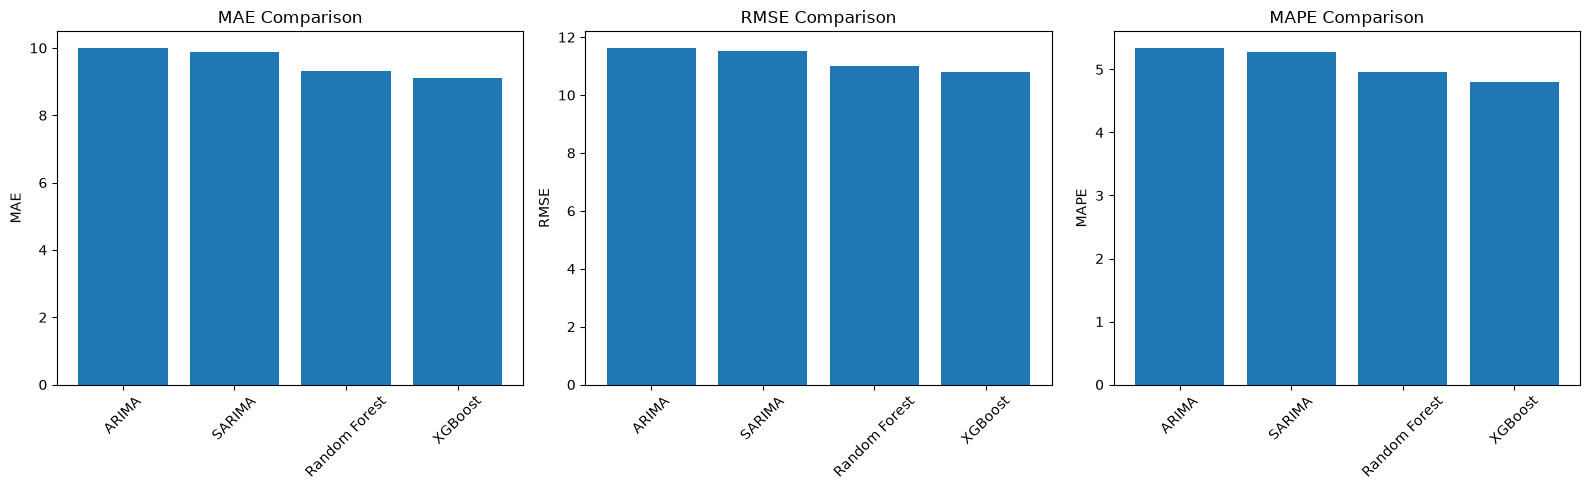

In [66]:
metrics = ['MAE', 'RMSE', 'MAPE']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, metric in enumerate(metrics):
    axes[i].bar(
        validation_comparison['Model'],
        validation_comparison[metric]
    )
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 19. Final Model Evaluation

After completing walk-forward validation, the forecasting models are evaluated on the final 30 trading days that were kept separate from the validation process.

This evaluation provides an independent assessment of model performance on unseen stock price data. The performance metrics are compared to identify how well the models generalize to the final test period.

### 19.1 Evaluating Model Predictions on the Test Set

The trained models are evaluated using the actual closing prices from the final 30 trading days. MAE, RMSE and MAPE are calculated to measure the prediction errors of each model on unseen data.

In [67]:
final_test_results = []

model_predictions = {
    'ARIMA': arima_predictions,
    'SARIMA': sarima_predictions,
    'Random Forest': rf_predictions,
    'XGBoost': xgb_predictions
}

for model_name, predictions in model_predictions.items():
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mape = np.mean(np.abs((y_test.values - np.array(predictions)) / y_test.values)) * 100

    final_test_results.append({
        'Model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

final_test_comparison = pd.DataFrame(final_test_results).round(4)

print(final_test_comparison)

           Model      MAE     RMSE    MAPE
0          ARIMA   7.5869  10.4651  2.7076
1         SARIMA   8.0411  11.0809  2.8687
2  Random Forest  10.2598  13.6118  3.6654
3        XGBoost  10.6514  13.9805  3.8079


### 19.2 Actual vs Predicted Stock Prices

The actual closing prices are compared with the predicted prices from all four forecasting models over the final 30 trading days. This visualization helps assess how closely each model follows the actual stock price movements.

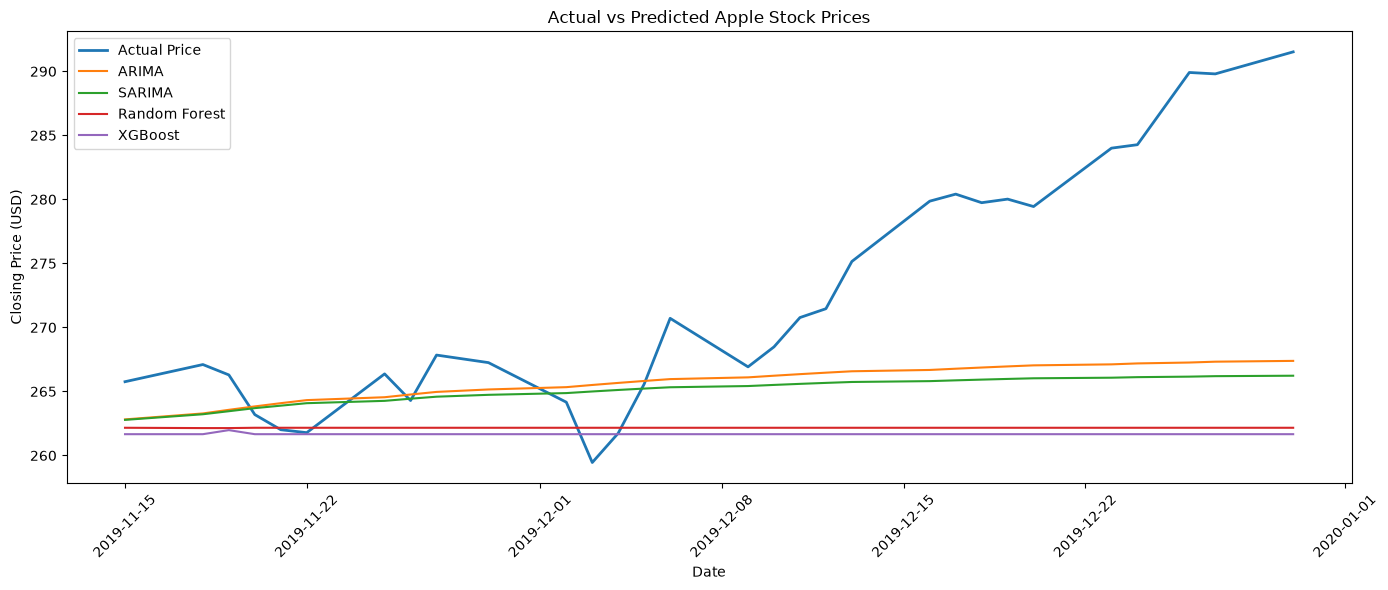

In [68]:
plt.figure(figsize=(14, 6))

plt.plot(test_data['Date'], y_test.values, label='Actual Price', linewidth=2)
plt.plot(test_data['Date'], arima_predictions, label='ARIMA')
plt.plot(test_data['Date'], sarima_predictions, label='SARIMA')
plt.plot(test_data['Date'], rf_predictions, label='Random Forest')
plt.plot(test_data['Date'], xgb_predictions, label='XGBoost')

plt.title('Actual vs Predicted Apple Stock Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 19.3 Comparison with the Baseline Model

The forecasting models are compared against a simple baseline that predicts the last observed training closing price for all 30 future trading days. This comparison helps determine whether the advanced models provide an improvement over a basic forecasting approach.

In [69]:
baseline_comparison = pd.DataFrame({
    'Model': ['30-Day Baseline', 'ARIMA', 'SARIMA', 'Random Forest', 'XGBoost'],
    'MAE': [
        baseline_30_mae,
        *final_test_comparison['MAE'].values
    ],
    'RMSE': [
        baseline_30_rmse,
        *final_test_comparison['RMSE'].values
    ],
    'MAPE': [
        baseline_30_mape,
        *final_test_comparison['MAPE'].values
    ]
})

print(baseline_comparison.round(4))

             Model      MAE     RMSE    MAPE
0  30-Day Baseline   9.9077  13.2636  3.5378
1            ARIMA   7.5869  10.4651  2.7076
2           SARIMA   8.0411  11.0809  2.8687
3    Random Forest  10.2598  13.6118  3.6654
4          XGBoost  10.6514  13.9805  3.8079


## 20. Final Model Selection

Based on the walk-forward validation and final test evaluation, ARIMA (1,1,3) is selected as the final forecasting model.

Although Random Forest achieved the lowest average errors during walk-forward validation, ARIMA performed better on the untouched final 30-day test period and outperformed the baseline model across all three evaluation metrics.

The results indicate that ARIMA provides the most suitable performance among the evaluated models for this dataset. However, the model has limitations in capturing sudden upward movements in stock prices.

## 21. Forecasting the Next 30 Trading Days

After selecting ARIMA (1,1,3) as the final model, it is retrained using the complete historical closing-price dataset. The trained model is then used to forecast Apple's closing prices for the next 30 trading days.

The forecast includes predicted values along with confidence intervals to represent the uncertainty associated with future predictions.

### 21.1 Training the Final ARIMA Model

The selected ARIMA (1,1,3) model is retrained using all available historical closing-price observations. This allows the final forecasting model to learn from the complete dataset before generating future predictions.

In [70]:
final_arima_model = ARIMA(
    data_model['Close'],
    order=(1, 1, 3)
)

final_arima_fitted = final_arima_model.fit()

print(final_arima_fitted.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1982
Model:                 ARIMA(1, 1, 3)   Log Likelihood               -4313.240
Date:                Mon, 16 Nov 2026   AIC                           8636.479
Time:                        15:04:52   BIC                           8664.436
Sample:                             0   HQIC                          8646.749
                               - 1982                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9596      0.023     41.086      0.000       0.914       1.005
ma.L1         -0.9529      0.028    -34.112      0.000      -1.008      -0.898
ma.L2         -0.0592      0.023     -2.542      0.0

### 21.2 Generating the 30-Day Forecast

The trained ARIMA model is used to predict Apple's closing prices for the next 30 trading days. Confidence intervals are also generated to understand the uncertainty associated with the forecasts.

In [71]:
forecast_result = final_arima_fitted.get_forecast(steps=30)

future_predictions = forecast_result.predicted_mean
confidence_intervals = forecast_result.conf_int()

market_holidays = pd.to_datetime([
    '2020-01-01',
    '2020-01-20'
])

available_dates = pd.bdate_range(
    start=data_model['Date'].iloc[-1] + pd.Timedelta(days=1),
    periods=32
)

forecast_dates = available_dates.difference(market_holidays)[:30]

forecast_df = pd.DataFrame({
    'Date': forecast_dates,
    'Predicted_Close': future_predictions.values,
    'Lower_CI': confidence_intervals.iloc[:, 0].values,
    'Upper_CI': confidence_intervals.iloc[:, 1].values
})

print(forecast_df.round(2))

         Date  Predicted_Close  Lower_CI  Upper_CI
0  2019-12-31           291.97    287.79    296.16
1  2020-01-02           292.28    286.34    298.21
2  2020-01-03           292.68    285.53    299.83
3  2020-01-06           293.07    284.84    301.30
4  2020-01-07           293.44    284.23    302.65
5  2020-01-08           293.80    283.67    303.93
6  2020-01-09           294.14    283.15    305.14
7  2020-01-10           294.47    282.66    306.29
8  2020-01-13           294.79    282.18    307.40
9  2020-01-14           295.09    281.72    308.47
10 2020-01-15           295.38    281.27    309.50
11 2020-01-16           295.66    280.83    310.50
12 2020-01-17           295.93    280.39    311.47
13 2020-01-21           296.19    279.96    312.42
14 2020-01-22           296.44    279.53    313.34
15 2020-01-23           296.67    279.11    314.24
16 2020-01-24           296.90    278.69    315.11
17 2020-01-27           297.12    278.28    315.96
18 2020-01-28           297.33 

In [72]:
market_holidays = pd.to_datetime([
    '2020-01-01',
    '2020-01-20'
])

available_dates = pd.bdate_range(
    start=data_model['Date'].iloc[-1] + pd.Timedelta(days=1),
    periods=32
)

forecast_dates = available_dates.difference(market_holidays)[:30]

forecast_df['Date'] = forecast_dates

print(forecast_df.round(2))

         Date  Predicted_Close  Lower_CI  Upper_CI
0  2019-12-31           291.97    287.79    296.16
1  2020-01-02           292.28    286.34    298.21
2  2020-01-03           292.68    285.53    299.83
3  2020-01-06           293.07    284.84    301.30
4  2020-01-07           293.44    284.23    302.65
5  2020-01-08           293.80    283.67    303.93
6  2020-01-09           294.14    283.15    305.14
7  2020-01-10           294.47    282.66    306.29
8  2020-01-13           294.79    282.18    307.40
9  2020-01-14           295.09    281.72    308.47
10 2020-01-15           295.38    281.27    309.50
11 2020-01-16           295.66    280.83    310.50
12 2020-01-17           295.93    280.39    311.47
13 2020-01-21           296.19    279.96    312.42
14 2020-01-22           296.44    279.53    313.34
15 2020-01-23           296.67    279.11    314.24
16 2020-01-24           296.90    278.69    315.11
17 2020-01-27           297.12    278.28    315.96
18 2020-01-28           297.33 

### 21.3 Visualization of the 30-Day Stock Price Forecast

The forecasted closing prices are visualized alongside historical stock prices. The confidence interval is displayed to illustrate the uncertainty surrounding the predicted values over the next 30 trading days.

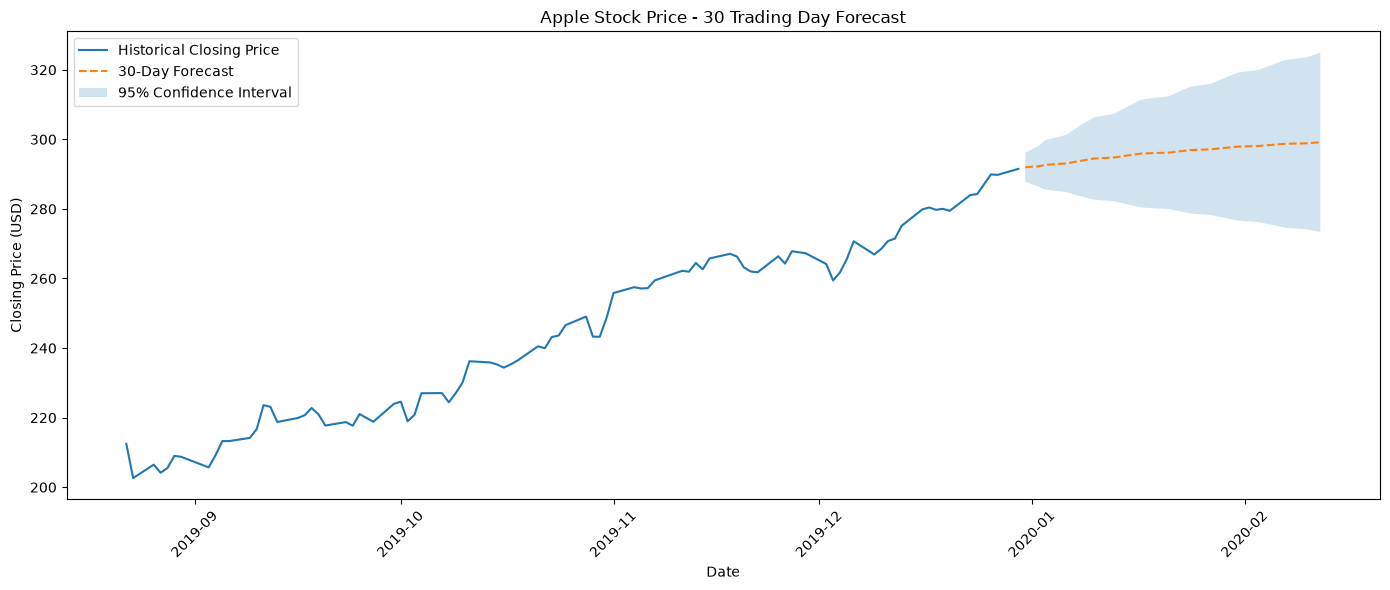

In [73]:
plt.figure(figsize=(14, 6))

plt.plot(
    data_model['Date'].iloc[-90:],
    data_model['Close'].iloc[-90:],
    label='Historical Closing Price'
)

plt.plot(
    forecast_df['Date'],
    forecast_df['Predicted_Close'],
    label='30-Day Forecast',
    linestyle='--'
)

plt.fill_between(
    forecast_df['Date'],
    forecast_df['Lower_CI'],
    forecast_df['Upper_CI'],
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title('Apple Stock Price - 30 Trading Day Forecast')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 22. Conclusion

This project focused on forecasting Apple's stock closing prices for the next 30 trading days using historical stock market data from 2012 to 2019.

Four forecasting models were developed and evaluated: ARIMA, SARIMA, Random Forest and XGBoost. Walk-forward validation and final holdout testing were used to assess their forecasting performance.

During walk-forward validation, Random Forest achieved the lowest average error, with an MAE of 9.3013, RMSE of 10.9410 and MAPE of 4.9460%. However, ARIMA (1,1,3) performed best on the final test dataset, achieving an MAE of 7.5869, RMSE of 10.4651 and MAPE of 2.7076%.

The selected ARIMA model was retrained using the complete historical dataset and used to generate a 30-trading-day forecast. The predicted closing price gradually increased from **$291.97 to $299.14** over the forecast period. Confidence intervals were also generated to represent the uncertainty associated with future predictions.

The results demonstrate that ARIMA (1,1,3) provided the best forecasting performance among the evaluated models on the final test dataset. The project also highlights the challenges of predicting stock prices, particularly when dealing with sudden market movements and increasing forecast uncertainty.

Overall, this project demonstrates the application of time-series forecasting, exploratory data analysis, feature engineering, model evaluation and hyperparameter tuning to a real-world financial prediction problem.

## 23. Limitations and Future Improvements

### Limitations

1. **Historical Data Dependency:** The models rely primarily on historical closing prices and may not capture unexpected market events.

2. **Market Volatility:** Sudden changes in stock prices are difficult to predict accurately using historical patterns alone.

3. **Limited External Indicators:** The current dataset does not include external financial indicators such as S&P 500 movements, inflation data or company earnings reports.

4. **Forecast Uncertainty:** The confidence intervals widen over the 30-day forecasting period, indicating increasing uncertainty in longer-term predictions.

5. **Model Generalization:** The difference between walk-forward validation and final test performance indicates that model performance can vary across market periods.

### Future Improvements

1. **External Financial Indicators:** Include external financial indicators such as S&P 500 data, inflation rates and Apple earnings reports.

2. **Advanced Forecasting Models:** Explore additional forecasting techniques such as LSTM and other advanced time-series models.

3. **Model Optimization:** Although Random Forest and XGBoost hyperparameters were tuned, further optimization and evaluation across different market conditions could improve forecasting performance.

4. **Technical Indicators:** Incorporate technical indicators such as RSI, MACD and Bollinger Bands.

5. **Application Development:** Develop an interactive forecasting application using Streamlit or Flask to display predictions and confidence intervals.

# Deployment 

In [75]:

import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# Page configuration
st.set_page_config(
    page_title="Apple Stock Prediction",
    page_icon="📈",
    layout="wide"
)

st.title("🍎 Apple Stock Price Prediction")
st.write("30 Trading Days Stock Price Forecasting using ARIMA")

st.sidebar.header("Upload Dataset")

uploaded_file = st.sidebar.file_uploader(
    "Upload Apple Stock CSV",
    type=["csv"]
)

# Load dataset
@st.cache_data
def load_data(file):
    data = pd.read_csv(file)

    data["Date"] = pd.to_datetime(data["Date"])
    data = data.sort_values("Date").reset_index(drop=True)

    data["Close"] = pd.to_numeric(
        data["Close"], errors="coerce"
    )

    data = data.dropna(subset=["Date", "Close"])

    return data

try:
    if uploaded_file is not None:
        data = load_data(uploaded_file)
    else:
        data = load_data("P721 DATASET.csv")

    if len(data) < 40:
        st.error("Please upload at least 40 valid stock records.")
        st.stop()

    # Dataset overview
    st.subheader("📊 Dataset Overview")

    col1, col2, col3 = st.columns(3)

    col1.metric("Total Records", len(data))
    col2.metric("Start Date", data["Date"].min().strftime("%Y-%m-%d"))
    col3.metric("End Date", data["Date"].max().strftime("%Y-%m-%d"))

    st.dataframe(data.tail(10), use_container_width=True)

    # Historical stock prices
    st.subheader("📈 Historical Closing Prices")

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        data["Date"],
        data["Close"],
        label="Closing Price"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Closing Price (USD)")
    ax.set_title("Apple Historical Stock Prices")
    ax.legend()
    ax.grid(True)

    st.pyplot(fig)
    plt.close(fig)

    # Descriptive statistics
    st.subheader("📋 Statistical Summary")
    st.dataframe(data.describe(), use_container_width=True)

    # ARIMA Model
    st.subheader("🤖 ARIMA Model Prediction")

    st.write("Selected Model: ARIMA (1,1,3)")

    if st.button("Generate 30-Day Forecast"):

        with st.spinner("Training ARIMA model..."):

            close_prices = data["Close"]

            model = ARIMA(
                close_prices,
                order=(1, 1, 3)
            )

            fitted_model = model.fit()

            # Forecast next 30 trading days
            forecast_result = fitted_model.get_forecast(
                steps=30
            )

            predictions = forecast_result.predicted_mean
            confidence = forecast_result.conf_int()

            # Generate future business dates
            forecast_dates = pd.bdate_range(
                start=data["Date"].iloc[-1] + pd.Timedelta(days=1),
                periods=30
            )

            forecast_df = pd.DataFrame({
                "Date": forecast_dates,
                "Predicted_Close": predictions.values,
                "Lower_CI": confidence.iloc[:, 0].values,
                "Upper_CI": confidence.iloc[:, 1].values
            })

            # Display forecast
            st.success("Forecast generated successfully!")

            st.subheader("📅 Next 30 Trading Days Prediction")

            st.dataframe(
                forecast_df.round(2),
                use_container_width=True
            )

            # Forecast graph
            st.subheader("📈 Actual vs Predicted Stock Prices")

            fig, ax = plt.subplots(figsize=(14, 6))

            ax.plot(
                data["Date"].iloc[-90:],
                data["Close"].iloc[-90:],
                label="Historical Price"
            )

            ax.plot(
                forecast_df["Date"],
                forecast_df["Predicted_Close"],
                linestyle="--",
                label="Predicted Price"
            )

            ax.fill_between(
                forecast_df["Date"],
                forecast_df["Lower_CI"],
                forecast_df["Upper_CI"],
                alpha=0.2,
                label="95% Confidence Interval"
            )

            ax.set_title("Apple Stock Price - 30 Day Forecast")
            ax.set_xlabel("Date")
            ax.set_ylabel("Closing Price (USD)")
            ax.legend()
            ax.grid(True)

            plt.xticks(rotation=45)
            plt.tight_layout()

            st.pyplot(fig)
            plt.close(fig)

            # Download predictions
            csv = forecast_df.to_csv(index=False)

            st.download_button(
                label="📥 Download Forecast CSV",
                data=csv,
                file_name="apple_stock_forecast.csv",
                mime="text/csv"
            )

            # Model summary
            with st.expander("View ARIMA Model Summary"):
                st.text(str(fitted_model.summary()))

except FileNotFoundError:
    st.error(
        "Dataset not found. Upload your Apple stock CSV file."
    )

except Exception as e:
    st.error(f"Error: {e}")

st.sidebar.info(
    "Forecasting Model: ARIMA (1,1,3)"
)

st.markdown("---")
st.caption("Apple Stock Price Prediction | Machine Learning Project")


2026-11-16 15:04:57.738 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 15:04:57.743 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 15:05:01.914 
  command:

    streamlit run C:\Users\Bhargavi\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-16 15:05:01.917 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 15:05:01.918 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 15:05:01.921 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 15:05:01.923 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when r

DeltaGenerator()